# TeasCo-FT · Tree Adapters

This notebook puts the whole `TeasCo-FT-TreeAdapters` project into one file. It covers the `teasco_tree` package, the benchmark and simulation scripts, and the key tests. The Streamlit UI is only summarised at the end.

## The idea

Requirements classification (for example *security-related* vs *not*) as a **teacher–student cascade**:

```
frozen Student SLM (local Ollama)  ─┐
                                    ├─> 385-dim features ─> tree adapter
sentence embedding (MiniLM, 384)   ─┘                        (XGBoost / CatBoost / LightGBM)
                                                              ^
70B Teacher LLM (offline, once) ── soft labels ──────────────┘
```

* **Features.** Each text becomes a 385-dim vector: a 384-dim MiniLM sentence embedding plus one number, the frozen local Student SLM's confidence.
* **Teacher.** A 70B LLM labels the *training* texts once, offline. It returns a probability distribution per text (soft labels).
* **Adapter.** The only trainable part is a gradient-boosted tree ensemble. There is no MLP anywhere. At inference time only the small local models run.
* **Gated update rule.** The adapter should *learn only from its mistakes*. Most of the technical work is porting that rule from neural backprop to boosting (Section 7).

## Where each file ended up

| Section | Original file(s) |
|---|---|
| 1 · Setup | `teasco_tree/__init__.py`, `_compat.py`, `system.py` |
| 2 · Data | `teasco_tree/data.py` |
| 3 · Student SLM | `llm/base.py`, `llm/ollama_student.py` |
| 4 · Teacher LLM | `llm/teacher.py` |
| 5 · Offline mocks | `llm/mock.py` |
| 6 · Features | `features/embeddings.py`, `features/builder.py` |
| 7 · Gated update rule | `adapters/gated_objective.py` |
| 8 · Tree adapters | `adapters/base.py`, `adapters/tree_adapters.py`, `adapters/__init__.py` |
| 9 · Pipeline | `teasco_tree/pipeline.py` |
| 10 · Plots | `teasco_tree/plots.py` |
| 11 · End-to-end run | `scripts/run_benchmark.py` |
| 12 · Simulations | `scripts/simulate_gate_modes.py` |
| 13 · Sanity checks | `tests/test_teacher.py`, `tests/test_ollama_llm.py` (condensed) |
| 14 · Appendix | `app.py`, `.streamlit/config.toml` |

> **How to run it.** Run the notebook from the project root, so that `data/` sits next to it. With `OFFLINE = True` (the default) everything runs in about a minute with no Ollama server, no API key and no model download. Mock models stand in for the Student and Teacher, so the scores only show that the plumbing works. Set `OFFLINE = False` to use the real models.

## 1 · Setup

### 1.1 Native runtime load order (why the first import matters)

On macOS, PyTorch, XGBoost and LightGBM each ship their **own copy of the OpenMP runtime** (`libomp.dylib`). The first copy loaded wins for the whole process. If PyTorch's copy loads first, XGBoost and LightGBM abort at *training* time:

```
OMP: Error #179: Function pthread_mutex_init failed
```

The abort cannot be caught as an exception, and `KMP_DUPLICATE_LIB_OK=TRUE` does not help. The only fix is load order, so **the boosting libraries are imported before anything can pull in torch** (`sentence-transformers` does). If torch was already imported, the adapters refuse to train and say why, instead of crashing the kernel.

> In a notebook, restart the kernel if you imported torch in an earlier session before running this cell.

In [1]:
import importlib
import os
import sys
import warnings
from typing import List

# Boosting libraries that must claim the OpenMP runtime before torch does.
_BOOSTING_MODULES = ("xgboost", "lightgbm")
# Modules loaded *after* torch in this process; training with them would abort.
_unsafe: "set[str]" = set()


def preload_boosting_runtimes(warn_on_late: bool = True) -> List[str]:
    """Import the OpenMP-linked boosting libraries ahead of torch (idempotent)."""
    if os.environ.get("TEASCO_TREE_NO_PRELOAD") == "1":
        return []
    torch_already_loaded = "torch" in sys.modules
    loaded = []
    for name in _BOOSTING_MODULES:
        # If the caller imported it themselves, we can't know the order they achieved.
        already_present = name in sys.modules
        try:
            importlib.import_module(name)
        except Exception:
            continue  # not installed: the adapter raises its own ImportError later
        loaded.append(name)
        if torch_already_loaded and not already_present:
            _unsafe.add(name)
    if _unsafe and warn_on_late:
        warnings.warn(f"torch was imported before {sorted(_unsafe)}; training those adapters "
                      "would abort with 'OMP: Error #179'. Restart the kernel.", RuntimeWarning)
    return loaded


def check_boosting_safe(module_name: str) -> None:
    """Turn the uncatchable OpenMP abort into an ordinary exception."""
    if module_name in _unsafe:
        raise RuntimeError(f"{module_name} was imported after torch, so its OpenMP runtime "
                           "conflicts with PyTorch's. Restart the kernel and run cells in order.")


print("Preloaded:", preload_boosting_runtimes())

Preloaded: ['xgboost', 'lightgbm']


### 1.2 Imports, paths and run switches

`OFFLINE` switches between the real models (Ollama Student + hosted 70B Teacher + MiniLM) and the mock models. The cache and run folders match the original project, so a run here reuses the Student/Teacher caches the Streamlit app already built, and the reverse.

In [2]:
import abc
import hashlib
import io
import json
import logging
import math
import re
import subprocess
import time
from abc import ABC, abstractmethod
from collections import Counter, deque
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any, Callable, Deque, Dict, Optional, Sequence, Tuple, Union

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
logger = logging.getLogger("teasco_tree")

# ── Paths (relative to the project root, where this notebook lives) ─────────
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
CACHE_DIR = PROJECT_ROOT / ".cache"      # Student / Teacher / feature caches
RUNS_DIR = PROJECT_ROOT / "runs"         # saved models, predictions, charts
RESULTS_DIR = PROJECT_ROOT / "results"   # simulation outputs

# ── Run switches ─────────────────────────────────────────────────────────────
OFFLINE = True            # True: mock Student/Teacher + hashing embedder, no network
RUN_SIMULATIONS = True    # Section 12; a few minutes at the quick settings below
SAVE_RUN = True           # write the demo run to runs/ (needed for Section 11.4)

assert DATA_DIR.exists(), f"Run this notebook from the project root; {DATA_DIR} not found."

### 1.3 Environment probes

These are small helpers the UI used to explain what can run on this machine: total memory (a local 70B Teacher needs about 48 GB), which Ollama models are pulled, and loading `.env` so the Teacher's API key never has to be typed into code.

In [3]:
def total_memory_gb() -> Optional[float]:
    """Physical memory in GB, or None if it cannot be determined."""
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024 ** 3
    except (ValueError, OSError, AttributeError):
        pass
    try:  # macOS fallback
        out = subprocess.run(["sysctl", "-n", "hw.memsize"], capture_output=True, text=True, timeout=5)
        return int(out.stdout.strip()) / 1024 ** 3
    except Exception:
        return None


def ollama_models(host: str = "http://localhost:11434") -> Optional[List[str]]:
    """Locally pulled Ollama model tags, or None if the server is unreachable."""
    try:
        import requests
        resp = requests.get(f"{host.rstrip('/')}/api/tags", timeout=3)
        resp.raise_for_status()
        return sorted(m["name"] for m in resp.json().get("models", []))
    except Exception:
        return None


def load_env(path) -> None:
    """Load KEY=VALUE lines from a .env file without overriding the real environment."""
    try:
        from dotenv import load_dotenv
        load_dotenv(path, override=False)
        return
    except ImportError:
        pass
    try:
        for line in open(path, encoding="utf-8"):
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                key, value = line.split("=", 1)
                os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))
    except FileNotFoundError:
        pass


load_env(PROJECT_ROOT / ".env")
mem = total_memory_gb()
print(f"Memory: {mem:.0f} GB" if mem else "Memory: unknown")
print("Ollama models:", "skipped (offline)" if OFFLINE else ollama_models())

Memory: 8 GB
Ollama models: skipped (offline)


## 2 · Data

Every dataset is reduced to a two-column frame: `text`, plus `label` when labels exist. Blank rows are dropped and **duplicate texts are removed**. That step matters: if the same requirement lands on both sides of a train/test split, the model has effectively seen the answer and every score comes out too high.

Three cleaned datasets ship in `data/`, all labelled `sec` / `nonsec`:

| Dataset | Rows | Notes |
|---|---|---|
| PROMISE | 969 | Requirements from 47 projects; 13% security-related |
| SecReq | 444 | Three security-focused specifications (CPN, GPS, ePurse) |
| NFR-SO | 16k | Stack Overflow titles; a stratified 400-row sample is used |

In [4]:
@dataclass
class Dataset:
    """A named list of texts with optional gold labels."""
    name: str
    texts: List[str]
    labels: Optional[List[str]] = None

    def __post_init__(self):
        if self.labels is not None and len(self.labels) != len(self.texts):
            raise ValueError(f"{self.name}: {len(self.texts)} texts but {len(self.labels)} labels.")

    @property
    def has_labels(self) -> bool:
        return self.labels is not None

    def __len__(self) -> int:
        return len(self.texts)


SAMPLE_DATASETS = {
    "PROMISE (sec vs nonsec)": {"path": DATA_DIR / "PROMISE_exp_clean.csv",
                                "about": "969 software requirements from 47 projects; 13% security-related."},
    "SecReq (CPN + GPS + ePurse)": {"path": DATA_DIR / "secreq_clean.csv",
                                    "about": "444 requirements from three security-focused specifications."},
    "NFR-SO (400-row sample)": {"path": DATA_DIR / "NFR_SO_clean.csv", "sample": 400,
                                "about": "Stack Overflow question titles tagged by NFR type; stratified sample."},
}

# Column-name hints used to guess which column is the text and which is the label.
_TEXT_HINTS = ("text", "requirement", "sentence", "content", "description", "title", "body")
_LABEL_HINTS = ("label", "class", "category", "target", "y", "tag")

### 2.1 Reading and cleaning

`read_table` accepts CSV, TSV, semicolon-delimited, Excel, Parquet and JSON/JSONL files. For delimited text it lets pandas *sniff* the delimiter, which handles SecReq's original headerless `<text>;<label>` format. `guess_columns` picks the text and label columns, first by name and then by content: the longest string column is taken as the text, and a column with only a few distinct values as the label.

In [5]:
def read_table(source: Union[str, Path, io.IOBase], name: Optional[str] = None) -> pd.DataFrame:
    """Read a CSV/TSV/semicolon file, Excel workbook, Parquet or JSON(L) file."""
    name = name or getattr(source, "name", None) or str(source)
    suffix = Path(name).suffix.lower()
    if suffix in (".xlsx", ".xls"):
        return pd.read_excel(source)
    if suffix == ".parquet":
        return pd.read_parquet(source)
    if suffix in (".json", ".jsonl"):
        return pd.read_json(source, lines=suffix == ".jsonl")

    raw = source.read() if hasattr(source, "read") else Path(source).read_bytes()
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8", errors="replace")
    try:
        df = pd.read_csv(io.StringIO(raw), sep=None, engine="python")  # sniff the delimiter
    except pd.errors.ParserError:
        df = pd.read_csv(io.StringIO(raw))
    if df.shape[1] == 1 and ";" in raw.splitlines()[0]:
        # Headerless `<text>;<label>` lines: split on the *last* semicolon only.
        rows = []
        for line in raw.splitlines():
            if ";" in line:
                text, label = line.strip().rsplit(";", 1)
                rows.append({"text": text.strip().strip('"'), "label": label.strip()})
        df = pd.DataFrame(rows)
    return df


def guess_columns(df: pd.DataFrame) -> Tuple[str, Optional[str]]:
    """Best guess at (text column, label column): by name first, then by content."""
    lowered = {c: str(c).lower() for c in df.columns}

    def by_hint(hints, exclude=None):
        for hint in hints:
            for col, low in lowered.items():
                if col != exclude and (low == hint or low.startswith(hint) or hint in low):
                    return col
        return None

    text_col = by_hint(_TEXT_HINTS)
    if text_col is None:  # fall back to the column with the longest strings
        object_cols = [c for c in df.columns if df[c].dtype == object]
        text_col = max(object_cols or list(df.columns), key=lambda c: df[c].astype(str).str.len().mean())

    label_col = by_hint(_LABEL_HINTS, exclude=text_col)
    if label_col is None:  # fall back to the column with the fewest (2..50) distinct values
        candidates = [c for c in df.columns if c != text_col and 1 < df[c].nunique() <= 50]
        label_col = min(candidates, key=lambda c: df[c].nunique()) if candidates else None
    return text_col, label_col


def clean_dataset(df: pd.DataFrame, text_col: str, label_col: Optional[str] = None,
                  min_chars: int = 3) -> pd.DataFrame:
    """Two-column frame (`text`, `label`?) with blanks and duplicate texts removed."""
    cols = [text_col] + ([label_col] if label_col else [])
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise KeyError(f"Columns {missing} not found. Present: {list(df.columns)}")

    out = df[cols].copy()
    out.columns = ["text"] + (["label"] if label_col else [])
    out = out.dropna(subset=["text"])
    out["text"] = out["text"].astype(str).str.strip()
    out = out[out["text"].str.len() >= min_chars]
    if label_col:
        out = out.dropna(subset=["label"])
        out["label"] = out["label"].astype(str).str.strip()
        out = out[out["label"].str.len() > 0]
    # De-duplication prevents the same text leaking across a train/test split.
    return out.drop_duplicates(subset=["text"]).reset_index(drop=True)


def to_dataset(df: pd.DataFrame, name: str) -> Dataset:
    """Wrap a cleaned frame from `clean_dataset`."""
    labels = df["label"].tolist() if "label" in df.columns else None
    return Dataset(name=name, texts=df["text"].tolist(), labels=labels)


def load_sample(name: str, random_state: int = 42) -> pd.DataFrame:
    """A shipped sample dataset, cleaned; large ones are stratified-subsampled."""
    spec = SAMPLE_DATASETS[name]
    df = clean_dataset(read_table(spec["path"]), "text", "label")
    n = spec.get("sample")
    if n and len(df) > n:
        df, _ = train_test_split(df, train_size=n, stratify=df["label"], random_state=random_state)
        df = df.reset_index(drop=True)
    return df

In [6]:
# Quick look at each shipped dataset after cleaning.
for sample_name, spec in SAMPLE_DATASETS.items():
    frame = load_sample(sample_name)
    print(f"{sample_name:30} {len(frame):4} rows  {frame['label'].value_counts().to_dict()}")
load_sample("PROMISE (sec vs nonsec)").head(3)

PROMISE (sec vs nonsec)         969 rows  {'nonsec': 844, 'sec': 125}
SecReq (CPN + GPS + ePurse)     444 rows  {'nonsec': 267, 'sec': 177}
NFR-SO (400-row sample)         400 rows  {'nonsec': 280, 'sec': 120}


,text,label
0,The system shall refresh the display every 60 ...,nonsec
1,The application shall match the color of the s...,nonsec
2,If projected the data must be readable. On a...,nonsec


## 3 · The frozen Student SLM

The Student is a small local model (default `qwen2.5:0.5b` on Ollama). It is never trained. It returns `(label, confidence)` for each text, and **only the confidence reaches the adapter**, as feature column 384. So a Student is judged by whether that number *varies with difficulty*, not by whether its label is right.

`model_name` is part of the feature-cache key, so changing the Student (or its scoring mode) can never reuse a stale feature matrix.

In [7]:
class BaseLLM(abc.ABC):
    """A frozen model returning `(labels, confidences)` for a list of texts."""

    @abc.abstractmethod
    def predict(self, texts: List[str], progress_callback=None) -> Tuple[List[str], np.ndarray]:
        """Labels and float32 confidences, one per text."""

    @property
    @abc.abstractmethod
    def model_name(self) -> str:
        """Identity string; part of the feature-cache key."""

### 3.1 Reading confidence from logprobs, not from the model's own claim

Two measured problems with small models shaped this design (50 balanced PROMISE requirements, `qwen2.5:0.5b`):

1. **Self-reported confidence is constant.** Asked to *state* a confidence, a 0.5B model says 0.9 or 1.0 for everything: 2 distinct values across 50 texts, which makes column 384 a dead feature. Reading the **first generated token's probability distribution** instead gives 50 distinct values (sd 0.11) that correlate with being right.
2. **Position bias.** In a forced choice the model mostly picks by option position. It answered 45/50 one way, then 44/50 the other way when only the option order was swapped. **Asking in both orders and averaging** cancels the bias: macro F1 went from 0.33 to 0.80, better than `llama3.2:3b` at about 9x the speed.

The options are shown as **letters** (`A) security-related  B) not security-related`) rather than class names, because names tokenise unevenly (`"sec"` is one token, `"nonsec"` starts with `"non"`). Only one token is generated, and its top-k probabilities are renormalised over the offered letters.

If the server returns no logprobs (Ollama < 0.12), the wrapper falls back **once** to a schema-constrained JSON reply. Every result is cached per text on disk, so an interrupted run resumes where it stopped.

In [8]:
_LETTERS = [chr(ord("A") + i) for i in range(26)]  # one option letter per class (max 26)


class OllamaLLM(BaseLLM):
    """Frozen local Student SLM served by Ollama; supplies feature column 384."""

    def __init__(self, classes: Sequence[str], model_name: str = "llama3.2:latest",
                 host: str = "http://localhost:11434", timeout: float = 60.0, max_retries: int = 3,
                 cache_path: Optional[str] = None, flush_every: int = 25, scoring: str = "logprobs",
                 top_logprobs: int = 20, debias: bool = True, class_descriptions: Optional[dict] = None):
        if scoring not in ("logprobs", "json"):
            raise ValueError(f"scoring must be 'logprobs' or 'json', got {scoring!r}")
        if len(classes) > len(_LETTERS):
            raise ValueError(f"logprob scoring offers one letter per class and there are only "
                             f"{len(_LETTERS)}; got {len(classes)} classes.")
        self.classes = list(classes)
        self._model_name = model_name
        self.host = host.rstrip("/")
        self.timeout, self.max_retries, self.flush_every = timeout, max_retries, flush_every
        self._fallback = self.classes[0]            # label used when a call cannot be parsed
        self.scoring, self.top_logprobs, self.debias = scoring, top_logprobs, debias
        self.class_descriptions = dict(class_descriptions or {})
        self._logprobs_unsupported = False          # flips once if the server has no logprobs
        # JSON-mode schema; Ollama enforces it server-side, so the label is always valid.
        self._schema = {"type": "object",
                        "properties": {"label": {"type": "string", "enum": self.classes},
                                       "confidence": {"type": "number"}},
                        "required": ["label", "confidence"]}
        # Per-text disk cache: {sha256(model_name + text): [label, confidence]}.
        self.cache_path = Path(cache_path) if cache_path else None
        self._cache = {}
        if self.cache_path and self.cache_path.exists():
            try:
                self._cache = json.loads(self.cache_path.read_text())
            except json.JSONDecodeError:
                logger.warning("Ollama cache at %s is corrupt; starting empty.", self.cache_path)
        self._dirty = 0
        self.failures = 0

    @property
    def model_name(self) -> str:
        # The scoring-mode suffix keeps the two modes from sharing a cached feature matrix.
        if self.scoring == "logprobs" and not self._logprobs_unsupported:
            return f"{self._model_name}{'#logprobs-debiased' if self.debias else '#logprobs'}"
        return self._model_name

    def is_available(self) -> bool:
        """True if the Ollama server is up and serving this model."""
        models = ollama_models(self.host)
        return models is not None and self._model_name in models

    # ── Cache ────────────────────────────────────────────────────────────────
    def _cache_key(self, text: str) -> str:
        return hashlib.sha256(f"{self.model_name}\x00{text}".encode("utf-8", errors="replace")).hexdigest()

    def _save_cache(self) -> None:
        if self.cache_path and self._dirty:
            self.cache_path.parent.mkdir(parents=True, exist_ok=True)
            self.cache_path.write_text(json.dumps(self._cache))
            self._dirty = 0

    # ── HTTP with exponential back-off ───────────────────────────────────────
    def _post_with_retry(self, payload: dict, on_success: Callable[[dict], Any], what: str):
        """POST to /api/chat; returns on_success(reply) or raises after max_retries."""
        import requests
        delay = 1.0
        for attempt in range(1, self.max_retries + 1):
            try:
                resp = requests.post(f"{self.host}/api/chat", json=payload, timeout=self.timeout)
                resp.raise_for_status()
                return on_success(resp.json())
            except Exception as exc:
                if attempt == self.max_retries:
                    logger.warning("Ollama %s call failed after %d attempts: %s", what, attempt, exc)
                    raise
                time.sleep(delay)
                delay *= 2

    # ── Logprob scoring (default) ────────────────────────────────────────────
    def _letter_distribution(self, text: str, order: List[str]) -> Optional[dict]:
        """One forced-choice call → {class: probability}, or None if unusable."""
        options = "  ".join(f"{_LETTERS[i]}) {self.class_descriptions.get(c, c)}" for i, c in enumerate(order))
        payload = {
            "model": self._model_name,
            "messages": [
                {"role": "system", "content": "You classify software requirements. Answer with a "
                                              "single letter only, no punctuation and no explanation."},
                {"role": "user", "content": f'Requirement: "{text[:1000]}"\n\n'
                                            f"Which option applies?\n{options}\n\nAnswer:"},
            ],
            "options": {"temperature": 0, "num_predict": 1},  # one token is all that is scored
            "logprobs": True, "top_logprobs": self.top_logprobs, "stream": False,
        }

        def parse(reply):
            steps = reply.get("logprobs") or []
            if not steps or not steps[0].get("top_logprobs"):
                # Server does not support logprobs: switch to JSON for the rest of the run.
                self._logprobs_unsupported = True
                logger.warning("No logprobs from %s (needs Ollama >= 0.12); using JSON confidence.",
                               self._model_name)
                return None
            valid = _LETTERS[:len(order)]
            mass = {c: 0.0 for c in order}
            for entry in steps[0]["top_logprobs"]:
                token = str(entry.get("token", "")).strip().upper()
                if token in valid:
                    mass[order[valid.index(token)]] += math.exp(float(entry["logprob"]))
            total = sum(mass.values())
            # Renormalise over the offered letters; None if the model answered something else.
            return {c: m / total for c, m in mass.items()} if total > 0 else None

        try:
            return self._post_with_retry(payload, parse, "logprob")
        except Exception:
            return None

    def _classify_one_logprobs(self, text: str) -> Optional[Tuple[str, float]]:
        """Average the class distribution over both option orders (cancels position bias)."""
        orders = [list(self.classes)]
        if self.debias and len(self.classes) > 1:
            orders.append(list(reversed(self.classes)))
        totals, n_ok = {c: 0.0 for c in self.classes}, 0
        for order in orders:
            probs = self._letter_distribution(text, order)
            if probs is None:
                if self._logprobs_unsupported:
                    return None
                continue
            for c, v in probs.items():
                totals[c] += v
            n_ok += 1
        if n_ok == 0:
            return None
        label = max(totals, key=totals.get)
        return label, float(totals[label] / n_ok)

    # ── JSON scoring (fallback) ──────────────────────────────────────────────
    def _classify_one_json(self, text: str) -> Tuple[str, float]:
        payload = {
            "model": self._model_name,
            "messages": [
                {"role": "system", "content": f"You are a requirements-engineering classifier. Classify the "
                                              f"requirement as one of: {', '.join(self.classes)}. "
                                              f"Respond with strict JSON only."},
                {"role": "user", "content": f'Requirement: "{text[:1000]}"\nRespond as JSON: '
                                            f'{{"label": one of {self.classes}, "confidence": number between 0 and 1}}'},
            ],
            "format": self._schema, "options": {"temperature": 0}, "stream": False,
        }

        def parse(reply):
            parsed = json.loads(reply["message"]["content"])
            label = str(parsed["label"]).strip().lower()
            return (label if label in self.classes else self._fallback,
                    min(max(float(parsed["confidence"]), 0.0), 1.0))

        try:
            return self._post_with_retry(payload, parse, "json")
        except Exception:
            self.failures += 1
            return self._fallback, 0.5

    def _classify_one(self, text: str) -> Tuple[str, float]:
        if self.scoring == "logprobs" and not self._logprobs_unsupported:
            result = self._classify_one_logprobs(text)
            if result is not None:
                return result
        return self._classify_one_json(text)

    def predict(self, texts: List[str], progress_callback=None) -> Tuple[List[str], np.ndarray]:
        """Classify each text (cache first), reporting progress after every text."""
        predictions, confidences = [], []
        for text in texts:
            key = self._cache_key(text)
            if key in self._cache:
                label, confidence = self._cache[key]
            else:
                label, confidence = self._classify_one(text)
                self._cache[key] = [label, confidence]
                self._dirty += 1
                if self._dirty >= self.flush_every:  # flush periodically so a crash loses little
                    self._save_cache()
            predictions.append(label)
            confidences.append(confidence)
            if progress_callback is not None:
                progress_callback(len(predictions), len(texts))
        self._save_cache()
        return predictions, np.asarray(confidences, dtype=np.float32)

## 4 · The 70B Teacher LLM

The Teacher labels the training texts **once, offline**, returning a probability distribution per text. It works with any OpenAI-compatible endpoint (OpenRouter, Together, Groq, Ollama's `/v1`, vLLM, …). The default is Llama 3.3 70B Instruct on OpenRouter: roughly one US cent for an 800-text training set.

### 4.1 Why Teacher failures must be loud

This section guards against one specific incident. A Teacher run hit its provider's tokens-per-minute quota, every retry was used up within three seconds, and **96% of texts fell back to a uniform distribution**. A uniform distribution is a *tie*, and `argmax` breaks ties toward the first class. The result was a training set that was 97% one constant label, and every adapter trained on it predicted a single class. It looked like a modelling problem, not an API problem.

The defences:

* **Failure budget.** If more than `max_failure_rate` (5%) of texts fail, raise `TeacherFailureError`. Failed rows are recorded in `failed_indices` and dropped before training.
* **Separate retry budgets.** A 429 means "your quota refills in N seconds". It gets its own, larger retry allowance and waits as long as the provider asks, **capped at 120 s**: Groq once asked for 974 s and then served the same request a minute later.
* **Daily quotas fail fast.** A per-*day* 429 will not clear within minutes, so retrying only burns time. It raises `DailyQuotaExhausted` immediately.
* **Client-side throttle.** A sliding 60-second window over *both* tokens and requests. Limits are discovered from the `x-ratelimit-limit-*` response headers and applied with a 0.9 safety factor.

In [9]:
# 70B Teacher configurations; `api_key_env` names the env var holding the key (None = local).
TEACHER_PRESETS: Dict[str, Dict[str, object]] = {
    "openrouter-llama-3.3-70b": {
        "label": "Llama 3.3 70B Instruct — OpenRouter (hosted)",
        "model": "meta-llama/llama-3.3-70b-instruct",
        "base_url": "https://openrouter.ai/api/v1",
        "api_key_env": "OPENROUTER_API_KEY",
        # Never route to a provider that silently ignores JSON mode.
        "extra_body": {"provider": {"require_parameters": True}},
        "min_memory_gb": 0,
    },
    "ollama-llama3.3-70b": {
        "label": "Llama 3.3 70B — local Ollama (needs ~48 GB RAM)",
        "model": "llama3.3:70b", "base_url": "http://localhost:11434/v1",
        "api_key_env": None, "extra_body": None, "min_memory_gb": 48,
    },
    "custom": {
        "label": "Custom OpenAI-compatible endpoint",
        "model": "meta-llama/Llama-3.3-70B-Instruct-Turbo", "base_url": "https://api.together.xyz/v1",
        "api_key_env": "TOGETHER_API_KEY", "extra_body": None, "min_memory_gb": 0,
    },
}


class TeacherFailureError(RuntimeError):
    """Too many texts failed; distilling on uniform ties would collapse the adapter."""


class DailyQuotaExhausted(RuntimeError):
    """The provider's *daily* budget is spent; retrying cannot help."""

### 4.2 Rate limiting and 429 parsing

In [10]:
class _RateLimiter:
    """Sliding-window throttle over the trailing 60 s, on tokens *and* requests."""

    def __init__(self, tokens_per_minute: Optional[int] = None,
                 requests_per_minute: Optional[int] = None, safety_factor: float = 0.9):
        self.safety_factor = safety_factor
        self.tokens_per_minute = self._scale(tokens_per_minute)
        self.requests_per_minute = self._scale(requests_per_minute)
        self._window: Deque[List[float]] = deque()   # [timestamp, tokens] per request
        self._blocked_until = 0.0                    # hard stop after a 429

    def _scale(self, limit):
        return None if limit is None else max(1.0, limit * self.safety_factor)

    def configure(self, tokens_per_minute=None, requests_per_minute=None) -> None:
        """Adopt provider-advertised limits for any budget not already set."""
        if self.tokens_per_minute is None and tokens_per_minute:
            self.tokens_per_minute = self._scale(tokens_per_minute)
        if self.requests_per_minute is None and requests_per_minute:
            self.requests_per_minute = self._scale(requests_per_minute)

    def acquire(self, estimated_tokens: float) -> List[float]:
        """Block until the request fits in the window, then reserve it."""
        while True:
            now = time.monotonic()
            if now < self._blocked_until:
                time.sleep(self._blocked_until - now)
                continue
            while self._window and now - self._window[0][0] >= 60.0:  # drop entries older than 60 s
                self._window.popleft()
            wait = 0.0
            oldest = self._window[0][0] if self._window else now
            if self.tokens_per_minute is not None and self._window:
                if sum(e[1] for e in self._window) + estimated_tokens > self.tokens_per_minute:
                    wait = max(wait, 60.0 - (now - oldest))
            if self.requests_per_minute is not None and self._window:
                if len(self._window) + 1 > self.requests_per_minute:
                    wait = max(wait, 60.0 - (now - oldest))
            if wait <= 0.0:
                handle = [now, float(estimated_tokens)]
                self._window.append(handle)
                return handle
            time.sleep(min(wait, 60.0) + 0.05)

    @staticmethod
    def record(handle: List[float], actual_tokens: Optional[int]) -> None:
        """Replace a reservation's estimate with the real usage."""
        if actual_tokens is not None:
            handle[1] = float(actual_tokens)

    def penalize(self, seconds: float) -> None:
        """Stop all traffic for `seconds` (used on a 429)."""
        self._blocked_until = max(self._blocked_until, time.monotonic() + seconds)


# Groq says "tokens per day (TPD)"; OpenAI/Azure say "per day" / "requests per day".
_DAILY_LIMIT_RE = re.compile(r"per\s+day|\bTPD\b|\bRPD\b", re.IGNORECASE)


def _is_rate_limit(exc: Exception) -> bool:
    status = getattr(exc, "status_code", None) or getattr(getattr(exc, "response", None), "status_code", None)
    return status == 429 or type(exc).__name__ == "RateLimitError"


def _is_daily_limit(exc: Exception) -> bool:
    return bool(_DAILY_LIMIT_RE.search(str(exc)))


def _parse_duration(raw: str) -> Optional[float]:
    """'7.038s' / '1m30s' / '12' (bare seconds) → seconds; None if unparseable."""
    match = re.fullmatch(r"(?:(\d+(?:\.\d+)?)m)?(\d+(?:\.\d+)?)?s?", raw.strip())
    if not match or not any(match.groups()):
        return None
    return float(match.group(1) or 0.0) * 60.0 + float(match.group(2) or 0.0)


def _retry_after_seconds(exc: Exception) -> Optional[float]:
    """Provider's requested cool-off: headers first, then the message ('try again in 7.0s')."""
    headers = getattr(getattr(exc, "response", None), "headers", None)
    if headers:
        for name in ("retry-after", "x-ratelimit-reset-tokens", "x-ratelimit-reset-requests"):
            raw = headers.get(name)
            parsed = _parse_duration(str(raw)) if raw else None
            if parsed is not None:
                return parsed
    match = re.search(r"try again in ([\d.]+)\s*([a-z]*)", str(exc), re.IGNORECASE)
    return _parse_duration(match.group(1) + match.group(2)) if match else None

### 4.3 Prompts and the `OpenAITeacher`

Texts are sent **25 per call** by default. The system prompt is then paid for once per batch, which cuts tokens per text by roughly 2–3x. The model returns `{"results": [{"i": 0, "sec": 0.9, "nonsec": 0.1}, ...]}`. Entries that are missing or malformed (a skipped index, a truncated array) are **re-issued one at a time** instead of discarding the whole batch.

> **Bug fixed here.** In the original `teacher.py`, `generate_soft_labels` uses `progress_callback` without declaring it as a parameter. Every call raises `NameError`, which fails 21 of the 52 tests in `tests/` and breaks any real (non-mock) Teacher run through the pipeline. The version below adds the parameter.

In [11]:
_SYSTEM_PROMPT = """\
You are a precise text classification assistant.
Your task is to classify the given text into one of these categories: {classes}.

You MUST respond with ONLY a valid JSON object — no explanation, no markdown, no extra text.
The JSON must have exactly these keys: {classes_json}
The values must be floating-point probabilities that sum to exactly 1.0.

Example response for classes ["positive", "negative", "neutral"]:
{{"positive": 0.85, "negative": 0.10, "neutral": 0.05}}
"""

_USER_PROMPT = 'Classify the following text:\n\n"""{text}"""\n\nRespond with ONLY the JSON probability distribution.\n'

_BATCH_SYSTEM_PROMPT = """\
You are a precise text classification assistant.
You will be given a numbered list of texts. Classify EVERY one of them into one
of these categories: {classes}.

Judge each numbered text independently — do not let one text influence another.

You MUST respond with ONLY a valid JSON object — no explanation, no markdown, no extra text:
{{"results": [{{"i": <index>, {example_keys}}}, ...]}}

Rules:
- Emit exactly one entry per input index, using the same indices you were given.
- Each entry's probabilities must cover all of {classes_json} and sum to 1.0.

Example for classes ["positive", "negative"] and 2 inputs:
{{"results": [{{"i": 0, "positive": 0.85, "negative": 0.15}}, {{"i": 1, "positive": 0.03, "negative": 0.97}}]}}
"""

_BATCH_USER_PROMPT = "Classify each of the following {n} texts:\n\n{items}\n\nRespond with ONLY the JSON object containing all {n} results.\n"

In [12]:
class OpenAITeacher:
    """Soft-label Teacher over any OpenAI-compatible chat-completions endpoint."""

    def __init__(self, api_key: str, model: str, classes: List[str], base_url: Optional[str] = None,
                 batch_size: int = 25, max_retries: int = 3, retry_delay: float = 1.0,
                 temperature: float = 0.0, max_tokens: Optional[int] = None,
                 reasoning_effort: Optional[str] = None, tokens_per_minute: Optional[int] = None,
                 requests_per_minute: Optional[int] = None, max_rate_limit_retries: int = 8,
                 max_rate_limit_wait: float = 120.0, max_failure_rate: float = 0.05,
                 extra_body: Optional[Dict] = None, class_descriptions: Optional[Dict[str, str]] = None):
        from openai import OpenAI
        if batch_size < 1:
            raise ValueError(f"batch_size must be >= 1, got {batch_size}")
        self._classes = list(classes)
        self.model, self.batch_size = model, batch_size
        self.max_retries, self.retry_delay = max_retries, retry_delay
        self.temperature, self.max_tokens, self.reasoning_effort = temperature, max_tokens, reasoning_effort
        self.max_rate_limit_retries, self.max_rate_limit_wait = max_rate_limit_retries, max_rate_limit_wait
        self.max_failure_rate = max_failure_rate
        self.extra_body = dict(extra_body) if extra_body else None
        self.class_descriptions = dict(class_descriptions or {})

        self.failed_indices: List[int] = []   # rows that fell back to uniform; drop before training
        self.usage = self._empty_usage()
        self._limiter = _RateLimiter(tokens_per_minute, requests_per_minute)
        self._limits_discovered = tokens_per_minute is not None
        self._tokens_per_item = 80.0          # completion tokens per text, refined by EWMA
        self._client = OpenAI(api_key=api_key, **({"base_url": base_url} if base_url else {}))

    @staticmethod
    def _empty_usage():
        return {"calls": 0, "prompt_tokens": 0, "completion_tokens": 0, "total_tokens": 0, "rate_limit_hits": 0}

    @property
    def classes(self) -> List[str]:
        return self._classes

    # ── Public API ───────────────────────────────────────────────────────────
    def generate_soft_labels(self, texts: List[str], classes: Optional[List[str]] = None,
                             progress_callback=None) -> List[Dict[str, float]]:
        """One {class: prob} per text. Raises TeacherFailureError past the failure budget."""
        target = classes if classes is not None else self._classes
        texts = list(texts)
        total = len(texts)
        self.failed_indices, self.usage = [], self._empty_usage()
        if total == 0:
            return []

        results: List[Optional[Dict[str, float]]] = [None] * total
        for start in range(0, total, self.batch_size):
            chunk = list(range(start, min(start + self.batch_size, total)))
            if len(chunk) == 1:
                results[chunk[0]] = self._label_one(texts[chunk[0]], target, chunk[0])
            else:
                self._label_chunk(texts, chunk, target, results)
            if progress_callback is not None:
                progress_callback(chunk[-1] + 1, total)
            # Later successes cannot un-fail earlier texts, so stop as soon as the budget is blown.
            self._check_failure_budget(total)

        if self.failed_indices:
            logger.warning("%d text(s) fell back to uniform: %s", len(self.failed_indices), self.failed_indices[:20])
        return [r if r is not None else self._uniform(target) for r in results]

    def filter_failed(self, *sequences: Sequence) -> Tuple[List, ...]:
        """Drop the failed rows from parallel sequences (texts, labels, soft labels, ...)."""
        drop = set(self.failed_indices)
        return tuple([item for i, item in enumerate(seq) if i not in drop] for seq in sequences)

    # ── Failure accounting ───────────────────────────────────────────────────
    def _check_failure_budget(self, total: int) -> None:
        n_failed = len(self.failed_indices)
        if n_failed <= self.max_failure_rate * total:
            return
        raise TeacherFailureError(
            f"{n_failed}/{total} texts ({100 * n_failed / total:.1f}%) could not be labeled by {self.model} "
            f"and fell back to a uniform distribution, exceeding max_failure_rate={self.max_failure_rate:.0%}. "
            f"Uniform soft labels are a tie that argmax resolves to one constant class. Hit the rate limit "
            f"{self.usage['rate_limit_hits']} times. Failed indices: {self.failed_indices[:20]}")

    @staticmethod
    def _uniform(classes):
        return {c: 1.0 / len(classes) for c in classes}

    def _normalize(self, raw: Dict, classes: List[str]) -> Dict[str, float]:
        """Every class must be present; rescale to sum to 1."""
        missing = [c for c in classes if c not in raw]
        if missing:
            raise KeyError(f"Missing classes in LLM response: {missing}")
        dist = {c: float(raw[c]) for c in classes}
        s = sum(dist.values())
        if s <= 0 or not math.isfinite(s):
            raise ValueError("Probabilities sum to zero or are non-finite.")
        return {c: v / s for c, v in dist.items()}

    def _label_one(self, text, classes, index) -> Dict[str, float]:
        try:
            return self._execute_with_retry(lambda: self._single_call(text, classes),
                                            self._estimate_tokens([text]), f"single(len={len(text)})")
        except DailyQuotaExhausted:
            raise  # not this text's fault; every later text would fail the same way
        except Exception as exc:
            logger.error("All attempts failed for text %d: %s", index, exc)
            self.failed_indices.append(index)
            return self._uniform(classes)

    def _label_chunk(self, texts, chunk, classes, results) -> None:
        """Label a batch, then re-issue only the entries the batch call left out."""
        try:
            batch = [texts[i] for i in chunk]
            parsed = self._execute_with_retry(lambda: self._batch_call(batch, classes),
                                              self._estimate_tokens(batch), f"batch(n={len(chunk)})")
        except DailyQuotaExhausted:
            raise
        except Exception as exc:
            logger.warning("Batch of %d failed (%s); falling back to per-text calls.", len(chunk), exc)
            parsed = {}
        for position, index in enumerate(chunk):
            dist = parsed.get(position)
            results[index] = dist if dist is not None else self._label_one(texts[index], classes, index)

    # ── Retry loop: two separate budgets ─────────────────────────────────────
    def _execute_with_retry(self, operation, estimated_tokens: float, label: str):
        delay, attempts, rate_limit_attempts = self.retry_delay, 0, 0
        while True:
            handle = self._limiter.acquire(estimated_tokens)
            before = self.usage["total_tokens"]
            try:
                result = operation()
            except Exception as exc:
                self._limiter.record(handle, int(estimated_tokens))  # keep the reservation under strain
                if _is_rate_limit(exc):
                    if _is_daily_limit(exc):
                        raise DailyQuotaExhausted(f"{self.model}: the provider's daily quota is spent; "
                                                  f"re-run once it resets (completed texts are cached). "
                                                  f"Provider said: {exc}") from exc
                    self.usage["rate_limit_hits"] += 1
                    rate_limit_attempts += 1
                    if rate_limit_attempts > self.max_rate_limit_retries:
                        raise
                    requested = _retry_after_seconds(exc)
                    # Honour the provider's hint, capped; with no hint, back off 2, 4, 8, ... s.
                    cool_off = (min(60.0, 2.0 ** rate_limit_attempts) if requested is None
                                else min(requested, self.max_rate_limit_wait))
                    logger.warning("Rate limited on %s (%d/%d); waiting %.1fs", label,
                                   rate_limit_attempts, self.max_rate_limit_retries, cool_off)
                    self._limiter.penalize(cool_off + 0.25)
                    continue
                attempts += 1  # ordinary error: parse failure, network, ...
                if attempts >= self.max_retries:
                    raise
                time.sleep(delay)
                delay *= 2
                continue
            self._limiter.record(handle, self.usage["total_tokens"] - before)  # real spend
            return result

    def _estimate_tokens(self, batch: List[str]) -> float:
        """Rough pre-flight cost (~4 chars/token); corrected by the real usage afterwards."""
        return (sum(len(t[:4000]) for t in batch) + 600) / 4.0 + len(batch) * self._tokens_per_item

    # ── API calls ────────────────────────────────────────────────────────────
    def _create(self, messages, max_tokens: int, n_items: int):
        """One chat completion in JSON mode; records usage and discovers rate limits."""
        body = dict(self.extra_body or {})
        if self.reasoning_effort is not None:
            body["reasoning_effort"] = self.reasoning_effort
        raw = self._client.chat.completions.with_raw_response.create(
            model=self.model, messages=messages, temperature=self.temperature, max_tokens=max_tokens,
            response_format={"type": "json_object"}, extra_body=body or None)

        if not self._limits_discovered and raw.headers:  # adopt x-ratelimit-limit-* once
            self._limits_discovered = True

            def as_int(name):
                try:
                    return int(float(raw.headers.get(name))) if raw.headers.get(name) else None
                except (TypeError, ValueError):
                    return None
            self._limiter.configure(as_int("x-ratelimit-limit-tokens"), as_int("x-ratelimit-limit-requests"))

        response = raw.parse()
        usage = getattr(response, "usage", None)
        if usage is not None:
            self.usage["calls"] += 1
            self.usage["prompt_tokens"] += usage.prompt_tokens or 0
            self.usage["completion_tokens"] += usage.completion_tokens or 0
            self.usage["total_tokens"] += usage.total_tokens or 0
            if n_items and usage.completion_tokens:  # EWMA so one odd batch doesn't swing pacing
                self._tokens_per_item = 0.7 * self._tokens_per_item + 0.3 * usage.completion_tokens / n_items
        return response

    def _descriptions_block(self, classes) -> str:
        """Explain terse label codes ('PE', 'SE') to the model."""
        described = [c for c in classes if self.class_descriptions.get(c, c) != c]
        if not described:
            return ""
        return "\nWhat each category means:\n" + "\n".join(
            f'- "{c}": {self.class_descriptions[c]}' for c in described) + "\n"

    def _single_call(self, text: str, classes: List[str]) -> Dict[str, float]:
        system = _SYSTEM_PROMPT.format(classes=", ".join(f'"{c}"' for c in classes),
                                       classes_json=json.dumps(classes)) + self._descriptions_block(classes)
        response = self._create([{"role": "system", "content": system},
                                 {"role": "user", "content": _USER_PROMPT.format(text=text[:4000])}],
                                max_tokens=self.max_tokens or 512, n_items=1)
        content = response.choices[0].message.content
        if not content:
            raise ValueError("Empty completion (max_tokens likely too low).")
        return self._normalize(json.loads(content.strip()), classes)

    def _batch_call(self, batch: List[str], classes: List[str]) -> Dict[int, Dict[str, float]]:
        """{position: distribution}; may be incomplete — the caller repairs the gaps."""
        system = _BATCH_SYSTEM_PROMPT.format(
            classes=", ".join(f'"{c}"' for c in classes), classes_json=json.dumps(classes),
            example_keys=", ".join(f'"{c}": <prob>' for c in classes)) + self._descriptions_block(classes)
        items = "\n".join(f"{i}. {t[:4000]}" for i, t in enumerate(batch))
        response = self._create(
            [{"role": "system", "content": system},
             {"role": "user", "content": _BATCH_USER_PROMPT.format(n=len(batch), items=items)}],
            max_tokens=self.max_tokens or (300 + len(batch) * (40 + 12 * len(classes))),  # sized to the batch
            n_items=len(batch))
        content = response.choices[0].message.content
        if not content:
            raise ValueError("Empty completion (max_tokens likely too low).")
        payload = json.loads(content.strip())
        entries = payload.get("results") if isinstance(payload, dict) else payload
        if not isinstance(entries, list):
            raise ValueError(f"Expected a 'results' list, got {type(entries).__name__}")

        parsed: Dict[int, Dict[str, float]] = {}
        for entry in entries:
            try:
                position = int(entry["i"])
                if 0 <= position < len(batch) and position not in parsed:
                    parsed[position] = self._normalize(entry, classes)
            except (KeyError, TypeError, ValueError):
                continue  # skip malformed entries; they get retried individually
        if not parsed:
            raise ValueError("Batch response contained no usable entries.")
        return parsed

## 5 · Offline stand-ins

These deterministic mocks let the pipeline, the demo and the checks run with no Ollama server and no API key. Both read a **keyword signal** from the text (`encrypt`, `password`, `auth`, …), so a demo run gives non-trivial results rather than noise. Their scores still say nothing about the real models.

* `MockStudentLLM` has a confidence that grows with the number of cue words, plus a stable per-text jitter.
* `MockTeacher` has the same interface as `OpenAITeacher`, and can simulate failures at chosen indices.

In [13]:
_DEFAULT_CUES = ("secur", "encrypt", "password", "auth", "access", "privacy", "attack",
                 "unauthori", "login", "permission", "protect", "confidential", "audit")


def _cue_class_index(classes: Sequence[str], cue_class: Optional[str]) -> int:
    """Which class the cues vote for: explicit, else a 'sec'-like name (not 'nonsec'), else class 0."""
    if cue_class is not None:
        return list(classes).index(cue_class)
    for i, c in enumerate(classes):
        if "sec" in c.lower() and not c.lower().startswith("non"):
            return i
    return 0


def _stable_unit(text: str, salt: str) -> float:
    """Deterministic pseudo-random number in [0, 1) derived from the text."""
    return int.from_bytes(hashlib.sha256(f"{salt}\x00{text}".encode("utf-8", "replace")).digest()[:8], "big") / 2 ** 64


def _cue_score(text: str, cues: Sequence[str]) -> float:
    return float(sum(cue in text.lower() for cue in cues))


class MockStudentLLM(BaseLLM):
    """Keyword-driven Student whose confidence varies with the evidence."""

    def __init__(self, classes, cues=_DEFAULT_CUES, noise: float = 0.15, cue_class=None):
        self.classes = list(classes)
        self._cue = _cue_class_index(self.classes, cue_class)
        self.cues, self.noise = tuple(cues), noise

    @property
    def model_name(self) -> str:
        return "mock-student"

    def predict(self, texts, progress_callback=None):
        labels, confs, k = [], [], len(self.classes)
        for i, text in enumerate(texts):
            score = _cue_score(text, self.cues)
            jitter = (_stable_unit(text, "student") - 0.5) * 2 * self.noise
            if score > 0:   # cue words present → vote for the cue class, more cues = more confident
                label, conf = self.classes[self._cue], min(0.99, 0.6 + 0.12 * score + jitter)
            else:
                label, conf = self.classes[(self._cue + 1) % k], min(0.99, 0.55 + abs(jitter))
            labels.append(label)
            confs.append(max(1.0 / k, conf))
            if progress_callback is not None:
                progress_callback(i + 1, len(texts))
        return labels, np.asarray(confs, dtype=np.float32)


class MockTeacher:
    """Soft-label Teacher with the same interface as OpenAITeacher."""

    def __init__(self, classes, cues=_DEFAULT_CUES, fail_indices=None, cue_class=None):
        self._classes = list(classes)
        self._cue = _cue_class_index(self._classes, cue_class)
        self.cues, self.model = tuple(cues), "mock-teacher"
        self._fail = set(fail_indices or [])
        self.failed_indices: List[int] = []
        self.usage = {"calls": 0, "total_tokens": 0, "rate_limit_hits": 0}

    @property
    def classes(self):
        return self._classes

    def generate_soft_labels(self, texts, classes=None, progress_callback=None):
        k = len(self._classes)
        out, self.failed_indices = [], []
        for i, text in enumerate(texts):
            if i in self._fail:  # simulated failure → uniform tie, recorded
                self.failed_indices.append(i)
                out.append({c: 1.0 / k for c in self._classes})
                continue
            first = min(0.97, 0.15 + 0.3 * min(_cue_score(text, self.cues), 2.5) + 0.1 * _stable_unit(text, "teacher"))
            rest = (1.0 - first) / (k - 1)
            out.append({c: (first if j == self._cue else rest) for j, c in enumerate(self._classes)})
            if progress_callback is not None:
                progress_callback(i + 1, len(texts))
        self.usage["calls"] = len(texts)
        return out

## 6 · Features: the shared 385-dim representation

```
[ sentence embedding (384) | frozen-Student confidence (1) ]  =  385 dims
```

Building this matrix is the most expensive part of a run: every text is encoded with MiniLM, and the Student is queried once or twice per text. `FeatureBuilder` computes the matrix once and caches it as `.npz` under a **content hash** of *(embedder name, Student name, the texts themselves)*. Changing the texts, the encoder or the Student changes the key, so a stale cache can never quietly poison a run. (The older shape-only cache check allowed exactly that.)

Two embedders are available:

* `SentenceEmbedder` uses the real `all-MiniLM-L6-v2`. It runs locally, needs a ~90 MB download on first use, and imports torch lazily.
* `HashingEmbedder` is a 384-dim hashed bag of word uni/bi-grams. It needs no download, is much weaker, and exists for offline use.

In [14]:
EMBEDDING_DIM = 384
FEATURE_DIM = 385  # 384 embedding + 1 Student confidence


class SentenceEmbedder:
    """all-MiniLM-L6-v2 sentence embeddings as float32 numpy (loaded on first use)."""

    def __init__(self, model_name: str = "all-MiniLM-L6-v2", batch_size: int = 64, device: str = "auto"):
        self.model_name, self.batch_size, self.device = model_name, batch_size, device
        self._model = None

    def embed(self, texts: List[str]) -> np.ndarray:
        if self._model is None:
            from sentence_transformers import SentenceTransformer  # pulls in torch — after boosting libs
            self._model = SentenceTransformer(self.model_name, device=None if self.device == "auto" else self.device)
        vectors = self._model.encode(list(texts), batch_size=self.batch_size,
                                     show_progress_bar=False, convert_to_numpy=True)
        return np.asarray(vectors, dtype=np.float32)


class HashingEmbedder:
    """Deterministic 384-dim hashed bag of words — no model download."""
    model_name = "hashing-384"

    def __init__(self):
        from sklearn.feature_extraction.text import HashingVectorizer
        self._vectorizer = HashingVectorizer(n_features=EMBEDDING_DIM, ngram_range=(1, 2),
                                             alternate_sign=False, norm="l2", lowercase=True)

    def embed(self, texts: List[str]) -> np.ndarray:
        return self._vectorizer.transform(list(texts)).toarray().astype(np.float32)


class FeatureBuilder:
    """Build (and content-hash cache) the (N, 385) float32 matrix shared by all adapters."""

    def __init__(self, embedder, llm=None, cache_dir: Optional[str] = None):
        self.embedder, self.llm = embedder, llm
        self.cache_dir = Path(cache_dir) if cache_dir else None
        if self.cache_dir:
            self.cache_dir.mkdir(parents=True, exist_ok=True)

    def build(self, texts: Sequence[str], progress_callback=None) -> np.ndarray:
        """Columns 0..383 = embedding, column 384 = Student confidence."""
        texts = list(texts)
        cache_path = self._cache_path(texts)
        if cache_path is not None and cache_path.exists():
            X = np.load(cache_path)["X"]
            if X.shape == (len(texts), FEATURE_DIM):
                return X
            logger.warning("Cache shape mismatch at %s; rebuilding.", cache_path)  # truncated write

        embeddings = np.asarray(self.embedder.embed(texts), dtype=np.float32)
        if embeddings.shape != (len(texts), EMBEDDING_DIM):
            raise ValueError(f"Embedder returned {embeddings.shape}, expected ({len(texts)}, {EMBEDDING_DIM}).")

        if self.llm is not None:  # the slow part: one or two Student calls per text
            _, confidences = self.llm.predict(texts, progress_callback=progress_callback)
            confidences = np.asarray(confidences, dtype=np.float32).reshape(-1, 1)
        else:                     # documented no-signal mode
            confidences = np.zeros((len(texts), 1), dtype=np.float32)

        X = np.hstack([embeddings, confidences]).astype(np.float32)
        if cache_path is not None:
            np.savez_compressed(cache_path, X=X)
        return X

    def _cache_path(self, texts: List[str]) -> Optional[Path]:
        """feat_<sha256(embedder, llm, texts)[:16]>.npz, or None when caching is off."""
        if self.cache_dir is None:
            return None
        digest = hashlib.sha256()
        for part in (getattr(self.embedder, "model_name", type(self.embedder).__name__),
                     getattr(self.llm, "model_name", "none") if self.llm else "none", *texts):
            digest.update(str(part).encode("utf-8", errors="replace"))
            digest.update(b"\x00")  # separator so ("ab","c") and ("a","bc") hash differently
        return self.cache_dir / f"feat_{digest.hexdigest()[:16]}.npz"

## 7 · The gated update rule for boosted trees

The TeasCo-FT V2 spec says the adapter must **learn only from its mistakes**: samples it already classifies correctly contribute no update. The original MLP did this by zeroing the *loss* of correct samples. A boosted ensemble has no weights to backpropagate into. Each round fits a new tree to the per-sample **gradient and hessian** of the loss with respect to the current margin, so the faithful translation is to zero those statistics directly.

For softmax cross-entropy with probabilities $p_i$ and (label-smoothed) one-hot target $Y_i$:

$$
g_i = \begin{cases} 0 & \text{if sample } i \text{ is gated out} \\ p_i - Y_i & \text{otherwise} \end{cases}
\qquad
h_i = \begin{cases} \varepsilon & \text{if gated out} \\ 2\,p_i(1-p_i) & \text{otherwise} \end{cases}
$$

A tree's leaf value is $-\sum g / (\sum h + \lambda)$, which is about 0 wherever the gate is closed, so new trees can only fix current mistakes. Boosting recomputes margins every round, so the gate is **re-evaluated every round**, just as the MLP re-gated every mini-batch.

Three details matter:

* **$\varepsilon > 0$, not 0.** A zero hessian makes the leaf denominator degenerate. XGBoost's `min_child_weight` is also a sum of hessians, and a small positive value stops gated samples from holding open splits they contribute nothing to.
* **`gate_margin` prevents collapse.** A strict correctness gate breaks boosting. Round 1 starts from a constant margin, so every sample ties to class 0 and that entire class is silenced. Every surviving sample then pushes the same way, there is no contrast to split on, and XGBoost emits single-leaf trees forever. The fix is to silence a sample only when it is correct **and** its top-vs-runner-up probability gap exceeds `gate_margin` (0.10). At initialisation the gap is exactly 0, so the first rounds train ungated automatically. *Measured on PROMISE: `gate_margin=0` gave 0 splits and macro F1 0.38 (a constant model); `0.10` gave 222 splits and 0.72.*
* **Soft labels judge correctness per text.** With soft-label expansion (Section 9.2), each text appears once per class. Correctness must be judged against the text's own label (`gate_labels` = the Teacher's argmax), not the copy's. Otherwise the minority copy is always "wrong", is never silenced, and drags the model toward it.

In [15]:
def softmax(margins: np.ndarray) -> np.ndarray:
    """Numerically stable row-wise softmax of (N, K) margins."""
    shifted = margins - margins.max(axis=1, keepdims=True)
    exp = np.exp(shifted)
    return exp / exp.sum(axis=1, keepdims=True)


def gated_softmax_grad_hess(margins, y, num_classes, gate=True, label_smoothing=0.0, eps_hess=1e-6,
                            sample_weight=None, gate_margin=0.0, gate_labels=None):
    """Gradient and hessian (both (N, K) float32) of the optionally gated softmax cross-entropy."""
    proba = softmax(margins)

    # One-hot target, optionally label-smoothed to mirror the MLP's CrossEntropyLoss(label_smoothing=0.05).
    target = np.zeros_like(proba)
    target[np.arange(len(y)), y] = 1.0
    if label_smoothing > 0.0:
        target = target * (1.0 - label_smoothing) + label_smoothing / num_classes

    grad = proba - target
    hess = 2.0 * proba * (1.0 - proba)  # XGBoost's softmax hessian convention

    if gate:
        # "Correct" is judged against the text's own label when soft-label copies are in play.
        correct = proba.argmax(axis=1) == (y if gate_labels is None else gate_labels)
        if gate_margin > 0.0:
            top2 = np.partition(proba, -2, axis=1)
            confidence_gap = top2[:, -1] - top2[:, -2]
            silenced = correct & (confidence_gap > gate_margin)  # correct AND confidently so
        else:
            silenced = correct
        grad[silenced] = 0.0
        hess[silenced] = eps_hess

    if sample_weight is not None:  # class balancing and/or soft-label weights
        w = np.asarray(sample_weight, dtype=np.float64).reshape(-1, 1)
        grad, hess = grad * w, np.maximum(hess * w, eps_hess)  # hessian stays strictly positive

    return grad.astype(np.float32), hess.astype(np.float32)


def make_xgboost_gated_objective(num_classes, gate=True, label_smoothing=0.0, eps_hess=1e-6,
                                 sample_weight=None, gate_margin=0.0, warmup_rounds=0,
                                 rounds_completed=0, gate_labels=None) -> Callable:
    """Custom XGBoost `obj(preds, dtrain)` implementing the gated rule.

    `warmup_rounds` trains ungated first; `rounds_completed` counts trees from earlier
    stages so warmup spans the whole ensemble instead of restarting each stage.
    """
    state = {"round": rounds_completed}

    def objective(preds, dtrain):
        y = dtrain.get_label().astype(np.int64)
        margins = np.asarray(preds, dtype=np.float64)
        if margins.ndim == 1:  # older XGBoost hands over a flat (N*K,) array
            margins = margins.reshape(-1, num_classes)
        gate_now = gate and state["round"] >= warmup_rounds
        state["round"] += 1
        grad, hess = gated_softmax_grad_hess(margins, y, num_classes, gate=gate_now,
                                             label_smoothing=label_smoothing, eps_hess=eps_hess,
                                             sample_weight=sample_weight, gate_margin=gate_margin,
                                             gate_labels=gate_labels)
        # Return in whatever layout XGBoost gave us.
        return (grad.reshape(-1), hess.reshape(-1)) if np.asarray(preds).ndim == 1 else (grad, hess)

    return objective


def gate_sample_weights(predictions, y, gate_floor=0.0, base_weight=None) -> Tuple[np.ndarray, int]:
    """Staged gating: wrong rows weigh 1, correct rows keep `gate_floor`. Returns (weights, n_wrong)."""
    wrong = predictions != y
    weights = np.where(wrong, 1.0, gate_floor).astype(np.float64)
    if base_weight is not None:
        weights = weights * np.asarray(base_weight, dtype=np.float64)
    return weights, int(wrong.sum())

In [16]:
# Why gate_margin matters: at initialisation every margin is 0, so every sample "ties" to class 0.
m0 = np.zeros((6, 2))
y_demo = np.array([0, 0, 0, 1, 1, 1])
g_strict, _ = gated_softmax_grad_hess(m0, y_demo, 2, gate=True, gate_margin=0.0)
g_margin, _ = gated_softmax_grad_hess(m0, y_demo, 2, gate=True, gate_margin=0.10)
print("strict gate  — rows with a non-zero gradient:", np.flatnonzero(np.abs(g_strict).sum(1)))  # only class 1 left
print("margin 0.10  — rows with a non-zero gradient:", np.flatnonzero(np.abs(g_margin).sum(1)))  # all rows train

strict gate  — rows with a non-zero gradient: [3 4 5]
margin 0.10  — rows with a non-zero gradient: [0 1 2 3 4 5]


## 8 · Tree adapters: XGBoost, CatBoost and LightGBM

An *adapter* is the trainable head on top of the frozen models. It maps the 385-dim features to class probabilities. All three adapters share one interface and one training skeleton, and differ only in how they add trees and predict.

### 8.1 Gate modes

| Mode | How the rule is applied | Libraries |
|---|---|---|
| `objective` | The exact analogue of the MLP's gated loss: a custom softmax objective with `grad=0, hess=ε` for confidently-correct rows, re-gated **every round**. | XGBoost only (the one exposing a clean custom multiclass objective) |
| `staged` | Library-agnostic. Train in blocks of 25 trees. Before each block the current ensemble predicts on the training set, correct rows are down-weighted to `gate_floor`, and the next block warm-starts from the existing ensemble. Re-gated **per stage**, like gating per epoch. | all three |
| `none` | Ungated control. Boosting already concentrates on residuals, so without this control any gain claimed for the gate cannot be tested. | all three |

**Why `gate_floor = 0.1` and not 0.** Strict staged gating (floor 0) overshoots. A stage retrained on *only* the current mistakes flips the rows it already had right, and validation F1 swung by up to **0.68** between stages in the simulations (Section 12). A floor of 0.1 gives the same scores without the swing.

### 8.2 Shared training loop

Each stage fits a block of trees, scores validation macro F1, and remembers the best ensemble size. Training stops after `patience` stages without improvement. Instead of snapshotting boosters, the best tree count is recorded and applied at prediction time (`iteration_range` / `num_iteration` / `ntree_end`). That is cheaper and avoids deep-copying large models.

**Class balancing with soft labels.** sklearn's `"balanced"` weights count rows per class. After soft-label expansion *every* class appears once per text, so counting rows would report every task as perfectly balanced. Class size is therefore measured as the summed Teacher probability mass instead.

In [17]:
GATE_MODES_ALL = ("objective", "staged", "none")


def _balanced_weights(y: np.ndarray, sample_weight: Optional[np.ndarray] = None) -> np.ndarray:
    """sklearn 'balanced' weighting, computed over weighted class *mass* when weights are given."""
    if sample_weight is None:
        return compute_sample_weight("balanced", y)
    classes = np.unique(y)
    mass = np.array([sample_weight[y == c].sum() for c in classes])
    per_class = sample_weight.sum() / (len(classes) * np.maximum(mass, 1e-12))
    lookup = dict(zip(classes, per_class))
    return sample_weight * np.array([lookup[c] for c in y])


class GatedBoostingAdapter(ABC):
    """Shared skeleton for gated gradient-boosted adapters (subclasses add/predict trees)."""
    name = "base"

    def __init__(self, classes: List[str], gate_mode: str = "staged", n_estimators: int = 400,
                 rounds_per_stage: int = 25, patience: int = 6, learning_rate: float = 0.1,
                 max_depth: int = 6, subsample: float = 0.9, colsample: float = 0.8,
                 reg_lambda: float = 1.0, gate_floor: float = 0.0, class_weight: Optional[str] = None,
                 label_smoothing: float = 0.05, gate_margin: float = 0.10, warmup_rounds: int = 0,
                 random_state: int = 42, verbose: bool = False, **extra_params: Any):
        if gate_mode not in GATE_MODES_ALL:
            raise ValueError(f"gate_mode must be one of {GATE_MODES_ALL}, got {gate_mode!r}.")
        self.classes, self.num_classes = list(classes), len(classes)
        self.gate_mode, self.n_estimators, self.rounds_per_stage = gate_mode, n_estimators, rounds_per_stage
        self.patience, self.learning_rate, self.max_depth = patience, learning_rate, max_depth
        self.subsample, self.colsample, self.reg_lambda = subsample, colsample, reg_lambda
        self.gate_floor, self.class_weight = gate_floor, class_weight
        self.label_smoothing, self.gate_margin, self.warmup_rounds = label_smoothing, gate_margin, warmup_rounds
        self.random_state, self.verbose, self.extra_params = random_state, verbose, extra_params
        self.n_stages = max(1, n_estimators // rounds_per_stage)
        self.history: Dict[str, List[float]] = {}
        self.best_val_f1, self.best_iteration, self.best_n_trees = 0.0, 0, 0
        self._gate_labels = None
        self._fitted = False

    # ── Hooks implemented per library ────────────────────────────────────────
    @abstractmethod
    def _fit_stage(self, X, y, weights, n_rounds: int, first_stage: bool) -> None:
        """Add `n_rounds` trees, warm-starting from the current ensemble."""

    @abstractmethod
    def _raw_predict_proba(self, X, n_trees: Optional[int] = None) -> np.ndarray:
        """Probabilities using only the first `n_trees` trees (None/0 = all)."""

    @property
    @abstractmethod
    def _current_n_trees(self) -> int: ...

    # ── Training ─────────────────────────────────────────────────────────────
    def fit(self, X, y, X_val=None, y_val=None, sample_weight=None, gate_labels=None) -> Dict[str, Any]:
        """Train under the gated rule with early stopping on validation macro F1.

        `sample_weight` carries soft-label weights (Section 9.2); `gate_labels` is each
        expanded row's source-text label, used by the gate and the reported train F1.
        """
        t_start = time.time()
        X = np.ascontiguousarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.int64)
        has_val = X_val is not None and y_val is not None
        gate_y = y if gate_labels is None else np.asarray(gate_labels, dtype=np.int64)
        self._gate_labels = None if gate_labels is None else gate_y

        base_weight = None if sample_weight is None else np.asarray(sample_weight, dtype=np.float64)
        if self.class_weight == "balanced":
            base_weight = _balanced_weights(y, base_weight)

        self.history = {"train_macro_f1": [], "val_macro_f1": [], "gate_ratio": [], "n_trees": []}
        best_val_f1, best_stage, patience_counter, stage = 0.0, 0, 0, 0
        self.best_n_trees = 0
        train_proba = None  # end-of-stage predictions = exactly the ensemble the next stage gates on

        for stage in range(1, self.n_stages + 1):
            first = stage == 1
            if self.gate_mode == "staged" and not first:
                weights, n_incorrect = gate_sample_weights(train_proba.argmax(axis=1), gate_y,
                                                           gate_floor=self.gate_floor, base_weight=base_weight)
                gate_ratio = n_incorrect / len(y)
                if n_incorrect == 0:  # nothing wrong → nothing to learn from
                    break
            else:
                weights, gate_ratio = base_weight, 1.0  # objective mode gates inside the loss

            self._fit_stage(X, y, weights, self.rounds_per_stage, first)

            train_proba = self._raw_predict_proba(X)
            train_f1 = f1_score(gate_y, train_proba.argmax(axis=1), average="macro", zero_division=0)
            val_f1 = (f1_score(y_val, self._raw_predict_proba(X_val).argmax(axis=1), average="macro", zero_division=0)
                      if has_val else 0.0)
            n_trees = self._current_n_trees
            for key, value in (("train_macro_f1", float(train_f1)), ("val_macro_f1", float(val_f1)),
                               ("gate_ratio", float(gate_ratio)), ("n_trees", int(n_trees))):
                self.history[key].append(value)

            # Early stopping: remember the best size, stop after `patience` stages without gain.
            monitored = val_f1 if has_val else train_f1
            if monitored > best_val_f1:
                best_val_f1, best_stage, self.best_n_trees, patience_counter = monitored, stage, n_trees, 0
            else:
                patience_counter += 1
                if patience_counter >= self.patience:
                    break

        if self.best_n_trees == 0:
            self.best_n_trees = self._current_n_trees
        self._fitted = True
        self.best_val_f1, self.best_iteration = float(best_val_f1), best_stage
        return {"adapter": self.name, "gate_mode": self.gate_mode, "best_val_f1": self.best_val_f1,
                "best_iteration": best_stage, "best_n_trees": self.best_n_trees, "total_stages": stage,
                "elapsed_seconds": time.time() - t_start, "history": self.history}

    # ── Prediction ───────────────────────────────────────────────────────────
    def _check_fitted(self):
        if not self._fitted:
            raise RuntimeError(f"{type(self).__name__} is not fitted. Call .fit(X, y) first.")

    def predict_proba(self, X) -> np.ndarray:
        """Class probabilities using the early-stopped ensemble size."""
        self._check_fitted()
        return self._raw_predict_proba(np.ascontiguousarray(X, dtype=np.float32), n_trees=self.best_n_trees)

    def predict(self, X) -> np.ndarray:
        return self.predict_proba(X).argmax(axis=1)

    def evaluate(self, X, y) -> Dict[str, float]:
        preds = self.predict(X)
        return {"macro_f1": float(f1_score(y, preds, average="macro", zero_division=0)),
                "weighted_f1": float(f1_score(y, preds, average="weighted", zero_division=0)),
                "accuracy": float((preds == y).mean())}

### 8.3 The three libraries

* **XGBoost** is the only adapter supporting `objective` mode. It always predicts raw margins and applies softmax itself, because with a custom objective XGBoost cannot know the right output transform.
* **CatBoost** chains stages through a `Pool` **baseline** (the current raw margin) and merges them with `sum_models`. It deliberately does *not* use `fit(init_model=...)`. Measured on CatBoost 1.2.10, the first continuation from a model silently ignores `sample_weight`, so under `init_model` the gate did nothing: `staged` and `none` produced byte-identical ensembles.
* **LightGBM** warm-starts with `init_model`. Its custom multiclass objectives use a class-major layout, so `objective` mode falls back to `staged`.

A saved model file contains *every* tree trained, including those past the early-stopping point. `best_n_trees` is therefore stored in the run manifest and passed back on load.

In [18]:
class XGBoostAdapter(GatedBoostingAdapter):
    name = "xgboost"

    def __init__(self, classes, gate_mode="objective", **kwargs):
        super().__init__(classes=classes, gate_mode=gate_mode, **kwargs)
        import xgboost as xgb
        check_boosting_safe("xgboost")  # fail loudly now rather than abort mid-training
        self._xgb, self._booster = xgb, None

    def _params(self):
        return {"objective": "multi:softprob", "num_class": self.num_classes, "eta": self.learning_rate,
                "max_depth": self.max_depth, "subsample": self.subsample, "colsample_bytree": self.colsample,
                "lambda": self.reg_lambda, "seed": self.random_state, "nthread": -1,
                "disable_default_eval_metric": 1,  # a custom objective has no matching built-in metric
                **self.extra_params}

    def _fit_stage(self, X, y, weights, n_rounds, first_stage):
        dtrain = self._xgb.DMatrix(X, label=y, weight=weights)
        obj = None
        if self.gate_mode == "objective":
            # Weights go into the objective so the gate and class balancing compose cleanly.
            obj = make_xgboost_gated_objective(
                num_classes=self.num_classes, gate=True, label_smoothing=self.label_smoothing,
                sample_weight=weights, gate_margin=self.gate_margin, warmup_rounds=self.warmup_rounds,
                rounds_completed=self._current_n_trees, gate_labels=self._gate_labels)
        self._booster = self._xgb.train(self._params(), dtrain, num_boost_round=n_rounds,
                                        xgb_model=None if first_stage else self._booster,
                                        obj=obj, verbose_eval=False)

    def _raw_predict_proba(self, X, n_trees=None):
        margins = self._booster.predict(self._xgb.DMatrix(X), output_margin=True,
                                        iteration_range=(0, n_trees) if n_trees else (0, 0))
        margins = np.asarray(margins, dtype=np.float64)
        return softmax(margins.reshape(-1, self.num_classes) if margins.ndim == 1 else margins)

    @property
    def _current_n_trees(self):
        return 0 if self._booster is None else self._booster.num_boosted_rounds()

    def save(self, path):
        self._check_fitted()
        self._booster.save_model(path)

    def load(self, path, best_n_trees=None):
        self._booster = self._xgb.Booster()
        self._booster.load_model(path)
        self.best_n_trees = best_n_trees or self._booster.num_boosted_rounds()
        self._fitted = True
        return self


class CatBoostAdapter(GatedBoostingAdapter):
    name = "catboost"

    def __init__(self, classes, gate_mode="staged", **kwargs):
        if gate_mode == "objective":
            logger.warning("CatBoost has no NumPy multiclass custom objective; using gate_mode='staged'.")
            gate_mode = "staged"
        super().__init__(classes=classes, gate_mode=gate_mode, **kwargs)
        import catboost
        self._catboost, self._model = catboost, None

    def _params(self):
        return {"learning_rate": self.learning_rate, "depth": min(self.max_depth, 16),
                "l2_leaf_reg": self.reg_lambda, "loss_function": "MultiClass" if self.num_classes > 2 else "Logloss",
                "random_seed": self.random_state, "verbose": False, "allow_writing_files": False,
                **self.extra_params}

    def _raw_margin(self, X, n_trees=None):
        return np.asarray(self._model.predict(X, prediction_type="RawFormulaVal", ntree_end=n_trees or 0),
                          dtype=np.float64)

    def _fit_stage(self, X, y, weights, n_rounds, first_stage):
        if weights is not None and float(np.sum(weights)) <= 0:
            return  # CatBoost rejects an all-zero weight vector
        # Chain stages via the baseline (current raw margin), not init_model — see the note above.
        baseline = None if first_stage or self._model is None else self._raw_margin(X)
        stage_model = self._catboost.CatBoostClassifier(iterations=n_rounds, **self._params())
        stage_model.fit(self._catboost.Pool(X, y, weight=weights, baseline=baseline))
        self._model = stage_model if baseline is None else self._catboost.sum_models([self._model, stage_model])

    def _raw_predict_proba(self, X, n_trees=None):
        margin = self._raw_margin(X, n_trees)
        if self.num_classes == 2:  # Logloss: a single logit for class 1
            p1 = 1.0 / (1.0 + np.exp(-margin.reshape(-1)))
            return np.column_stack([1.0 - p1, p1])
        return softmax(margin.reshape(-1, self.num_classes))

    @property
    def _current_n_trees(self):
        return 0 if self._model is None else int(self._model.tree_count_)

    def save(self, path):
        self._check_fitted()
        self._model.save_model(path)

    def load(self, path, best_n_trees=None):
        self._model = self._catboost.CatBoost()
        self._model.load_model(path)
        self.best_n_trees = best_n_trees or int(self._model.tree_count_)
        self._fitted = True
        return self


class LightGBMAdapter(GatedBoostingAdapter):
    name = "lightgbm"

    def __init__(self, classes, gate_mode="staged", **kwargs):
        if gate_mode == "objective":
            logger.warning("LightGBM multiclass custom objectives use a class-major layout; using 'staged'.")
            gate_mode = "staged"
        super().__init__(classes=classes, gate_mode=gate_mode, **kwargs)
        import lightgbm as lgb
        check_boosting_safe("lightgbm")
        self._lgb, self._booster = lgb, None

    def _fit_stage(self, X, y, weights, n_rounds, first_stage):
        if weights is not None and float(np.sum(weights)) <= 0:
            return
        params = {"objective": "multiclass", "num_class": self.num_classes, "learning_rate": self.learning_rate,
                  "max_depth": self.max_depth, "num_leaves": min(2 ** self.max_depth, 63),
                  "feature_fraction": self.colsample, "bagging_fraction": self.subsample, "bagging_freq": 1,
                  "lambda_l2": self.reg_lambda, "seed": self.random_state, "verbose": -1,
                  "min_data_in_leaf": 5,  # dense embeddings, small N: keep leaves reachable
                  **self.extra_params}
        dtrain = self._lgb.Dataset(X, label=y, weight=weights, free_raw_data=False)
        self._booster = self._lgb.train(params, dtrain, num_boost_round=n_rounds,
                                        init_model=None if first_stage else self._booster)

    def _raw_predict_proba(self, X, n_trees=None):
        kwargs = {"num_iteration": n_trees} if n_trees else {}
        return np.asarray(self._booster.predict(X, **kwargs), dtype=np.float64)

    @property
    def _current_n_trees(self):
        return 0 if self._booster is None else self._booster.current_iteration()  # rounds, not per-class trees

    def save(self, path):
        self._check_fitted()
        self._booster.save_model(path, num_iteration=self.best_n_trees)

    def load(self, path, best_n_trees=None):
        self._booster = self._lgb.Booster(model_file=path)
        self.best_n_trees = best_n_trees or self._booster.current_iteration()
        self._fitted = True
        return self

### 8.4 Registry

In [19]:
ADAPTERS = {"xgboost": XGBoostAdapter, "catboost": CatBoostAdapter, "lightgbm": LightGBMAdapter}
_ALIASES = {"xgb": "xgboost", "cat": "catboost", "lgbm": "lightgbm", "lgb": "lightgbm"}
GATE_MODES = {"xgboost": ["objective", "staged", "none"], "catboost": ["staged", "none"], "lightgbm": ["staged", "none"]}
DEFAULT_GATE_MODE = {"xgboost": "objective", "catboost": "staged", "lightgbm": "staged"}
DISPLAY_NAME = {"xgboost": "XGBoost", "catboost": "CatBoost", "lightgbm": "LightGBM"}


def resolve_name(name: str) -> str:
    key = _ALIASES.get(name.lower(), name.lower())
    if key not in ADAPTERS:
        raise ValueError(f"Unknown adapter {name!r}. Available: {list(ADAPTERS)}")
    return key


def get_adapter(name: str, classes: List[str], **kwargs) -> GatedBoostingAdapter:
    """Instantiate a tree adapter by name (aliases such as 'xgb' accepted)."""
    return ADAPTERS[resolve_name(name)](classes=classes, **kwargs)

## 9 · The end-to-end pipeline

`run_experiment` takes one training set and any number of test sets through the whole cascade:

1. **Features.** MiniLM (384) + Student confidence (1) for every training and test text, cached by content.
2. **Teacher.** The 70B Teacher labels the *training* texts once, with a per-text soft-label cache so a re-run costs nothing.
3. **Adapters.** Each selected adapter is trained under each selected supervision signal:

| Supervision | Trained on |
|---|---|
| `ground_truth` | the dataset's own labels (needs a label column) |
| `teacher_hard` | the Teacher's argmax pseudo-labels |
| `teacher_soft` | the Teacher's full distributions: knowledge distillation proper, via row expansion |

4. **Evaluation.** Macro/weighted F1 and accuracy per test set, next to the majority-class baseline and the frozen Student's own zero-shot score.

### 9.1 Configuration

In [20]:
SUPERVISIONS = ("ground_truth", "teacher_hard", "teacher_soft")
SUPERVISION_LABEL = {"ground_truth": "Ground truth", "teacher_hard": "Teacher pseudo-labels",
                     "teacher_soft": "Teacher soft labels (KD)"}
_MODEL_EXT = {"xgboost": ".json", "catboost": ".cbm", "lightgbm": ".txt"}
ProgressFn = Callable[[str, float, str], None]   # progress(stage, fraction in [0, 1], message)


def _noop_progress(stage, fraction, message):
    pass


@dataclass
class StudentConfig:
    """The frozen Student SLM that supplies feature column 384."""
    backend: str = "ollama"            # "ollama" | "mock"
    model: str = "qwen2.5:0.5b"
    host: str = "http://localhost:11434"
    scoring: str = "logprobs"          # "logprobs" | "json"
    debias: bool = True


@dataclass
class TeacherConfig:
    """The offline 70B Teacher. `api_key` is excluded from repr and never written to disk."""
    backend: str = "api"               # "api" | "mock" | "none"
    model: str = "meta-llama/llama-3.3-70b-instruct"
    base_url: Optional[str] = "https://openrouter.ai/api/v1"
    api_key: Optional[str] = field(default=None, repr=False)
    extra_body: Optional[Dict[str, Any]] = None
    batch_size: int = 25
    max_failure_rate: float = 0.05
    tokens_per_minute: Optional[int] = None

    def public(self) -> Dict[str, Any]:
        data = asdict(self)
        data.pop("api_key", None)
        return data


@dataclass
class TrainConfig:
    """Adapters, supervision signals and boosting hyper-parameters."""
    adapters: List[str] = field(default_factory=lambda: ["xgboost", "catboost", "lightgbm"])
    supervisions: List[str] = field(default_factory=lambda: list(SUPERVISIONS))
    gate_modes: Dict[str, str] = field(default_factory=dict)   # per-adapter override
    embedder: str = "minilm"           # "minilm" | "hashing"
    class_weight: Optional[str] = "balanced"
    n_estimators: int = 400
    learning_rate: float = 0.1
    max_depth: int = 6
    rounds_per_stage: int = 25
    patience: int = 6
    gate_margin: float = 0.10
    gate_floor: float = 0.10           # 0.0 = strict, but validation F1 swings (Section 12)
    val_split: float = 0.15
    random_state: int = 42

    def gate_mode_for(self, adapter: str) -> str:
        return self.gate_modes.get(adapter, DEFAULT_GATE_MODE[adapter])

### 9.2 Building blocks

**Soft-label distillation for a model that only accepts hard labels.** Each training row becomes *one copy per class*, labelled with that class and weighted by the Teacher's probability for it:

$$
\sum_{k} p^{\text{teacher}}_{ik}\,\big(-\log q_{ik}\big) \;=\; \text{CE}\big(p^{\text{teacher}}_i,\; q_i\big)
$$

Weighted cross-entropy over the expanded set equals cross-entropy against the soft distribution. The trees therefore fit the Teacher's full belief, *including how sure it was*, not just its argmax. Copies with near-zero weight are dropped. `source_row` records which text each copy came from, so the gate can judge correctness per text.

In [21]:
def _slug(text: str) -> str:
    return "".join(ch if ch.isalnum() else "_" for ch in text).strip("_")


def _digest(*parts: Any) -> str:
    return hashlib.sha256(json.dumps(parts, sort_keys=True, default=str).encode()).hexdigest()[:12]


def make_student(cfg: StudentConfig, classes, class_descriptions=None):
    if cfg.backend == "mock":
        return MockStudentLLM(classes)
    student = OllamaLLM(classes=classes, model_name=cfg.model, host=cfg.host, scoring=cfg.scoring,
                        debias=cfg.debias, class_descriptions=class_descriptions,
                        # Class order and wording change the prompt, so they are part of the cache key.
                        cache_path=CACHE_DIR / "student" / f"{_slug(cfg.model)}_{_digest(list(classes), class_descriptions)}.json")
    if not student.is_available():
        raise RuntimeError(f"Student {cfg.model!r} is not served at {cfg.host}. "
                           f"Start Ollama and run `ollama pull {cfg.model}`.")
    return student


def make_teacher(cfg: TeacherConfig, classes, class_descriptions=None):
    if cfg.backend == "mock":
        return MockTeacher(classes)
    return OpenAITeacher(api_key=cfg.api_key or "not-needed-for-local-servers", model=cfg.model,
                         classes=list(classes), base_url=cfg.base_url, batch_size=cfg.batch_size,
                         max_failure_rate=cfg.max_failure_rate, tokens_per_minute=cfg.tokens_per_minute,
                         extra_body=cfg.extra_body, class_descriptions=class_descriptions)


def make_embedder(name: str):
    return {"hashing": HashingEmbedder, "minilm": SentenceEmbedder}[name]()


class SoftLabelCache:
    """Per-text Teacher soft labels on disk, keyed by model + classes + wording.
    Failed texts are never cached, so the next run retries them."""

    def __init__(self, model, classes, class_descriptions=None, cache_dir: Path = CACHE_DIR / "teacher"):
        self.path = Path(cache_dir) / f"{_slug(model)}_{_digest(list(classes), class_descriptions or {})}.json"
        self._data: Dict[str, Dict[str, float]] = {}
        if self.path.exists():
            try:
                self._data = json.loads(self.path.read_text())
            except json.JSONDecodeError:
                logger.warning("Teacher cache %s is corrupt; starting empty.", self.path)

    @staticmethod
    def key(text):
        return hashlib.sha256(text.encode("utf-8", "replace")).hexdigest()

    def get(self, text):
        return self._data.get(self.key(text))

    def put(self, text, dist):
        self._data[self.key(text)] = dist

    def save(self):
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.path.write_text(json.dumps(self._data))


def label_with_teacher(teacher, texts, classes, cache, progress: ProgressFn = _noop_progress):
    """Soft labels for every text, calling the Teacher only for uncached ones.
    Returns (soft_labels, failed_indices, usage); failed rows must be dropped before training."""
    soft: List[Optional[Dict[str, float]]] = [None] * len(texts)
    todo = []
    for i, text in enumerate(texts):
        hit = cache.get(text) if cache is not None else None
        if hit is not None and set(hit) == set(classes):
            soft[i] = hit
        else:
            todo.append(i)

    failed: List[int] = []
    usage = {"calls": 0, "total_tokens": 0, "cached": len(texts) - len(todo)}
    if todo:
        progress("teacher", 0.0, f"Teacher labeling {len(todo)} uncached texts ({usage['cached']} cached)")
        try:
            fresh = teacher.generate_soft_labels(
                [texts[i] for i in todo],
                progress_callback=lambda done, total: progress("teacher", done / total, f"Teacher labeled {done}/{total}"))
        finally:  # report usage even when the Teacher raises
            usage.update({k: v for k, v in getattr(teacher, "usage", {}).items()
                          if k in ("calls", "total_tokens", "rate_limit_hits")})
        failed_local = set(teacher.failed_indices)
        for j, i in enumerate(todo):
            soft[i] = fresh[j]
            if j in failed_local:
                failed.append(i)
            elif cache is not None:
                cache.put(texts[i], fresh[j])
        if cache is not None:
            cache.save()
    progress("teacher", 1.0, "Teacher labels ready")
    return soft, sorted(failed), usage


def expand_soft_labels(X, soft, min_weight: float = 1e-3):
    """Row expansion: (X_expanded, y_expanded, weights, source_row) — one weighted copy per class."""
    n, k = soft.shape
    rows = np.repeat(np.arange(n), k)      # 0,0,1,1,2,2,...  (for k=2)
    labels = np.tile(np.arange(k), n)      # 0,1,0,1,0,1,...
    weights = soft.reshape(-1)
    keep = weights >= min_weight           # near-zero copies contribute nothing
    return X[rows[keep]], labels[keep], weights[keep], rows[keep]


def majority_baseline_f1(labels) -> float:
    """Macro F1 of always predicting the most common class: the collapse floor."""
    majority = Counter(labels).most_common(1)[0][0]
    return float(f1_score(list(labels), [majority] * len(labels), average="macro", zero_division=0))


def _metrics(y_true, y_pred, classes) -> Dict[str, Any]:
    return {"macro_f1": float(f1_score(y_true, y_pred, labels=list(classes), average="macro", zero_division=0)),
            "weighted_f1": float(f1_score(y_true, y_pred, labels=list(classes), average="weighted", zero_division=0)),
            "accuracy": float(np.mean(np.asarray(y_true) == np.asarray(y_pred))),
            "confusion": confusion_matrix(y_true, y_pred, labels=list(classes)).tolist()}


def model_key(adapter: str, supervision: str) -> str:
    return f"{adapter}__{supervision}"

In [22]:
@dataclass
class ExperimentResult:
    classes: List[str]
    config: Dict[str, Any]
    train_size: int
    fit_summaries: List[Dict[str, Any]]
    eval_rows: List[Dict[str, Any]]
    reference_rows: List[Dict[str, Any]]
    diagnostics: Dict[str, Any]
    warnings: List[str]
    predictions: Dict[str, List[Dict[str, Any]]]
    timings: Dict[str, float]
    models: Dict[str, Any] = field(default_factory=dict, repr=False)
    feature_builder: Any = field(default=None, repr=False)
    run_dir: Optional[Path] = None

    def payload(self) -> Dict[str, Any]:
        """JSON-serialisable summary (no models, no API key) — the input to every plot."""
        return {"classes": self.classes, "config": self.config, "train_size": self.train_size,
                "fit_summaries": self.fit_summaries, "results": self.eval_rows,
                "reference": self.reference_rows, "diagnostics": self.diagnostics,
                "warnings": self.warnings, "timings": self.timings}

    def predict(self, texts: List[str], model_key: str):
        proba = self.models[model_key].predict_proba(self.feature_builder.build(list(texts)))
        return [self.classes[i] for i in proba.argmax(axis=1)], proba

### 9.3 `run_experiment` and the three collapse guards

This pipeline fails *silently*: a model that predicts one class for everything still posts a plausible 0.1–0.4 macro F1. Three guards run on every run and write to `warnings`:

1. **Dead Student feature.** The Student's confidence column must not be constant.
2. **Constant Teacher.** The Teacher must not give every text the same label. If it does, the Teacher supervisions are dropped, or the run fails if nothing else is left.
3. **Collapsed adapter.** No trained adapter may predict a single class on a test set.

Teacher-supervised variants also **validate against Teacher labels**, so the gold labels never leak into a run that claims to learn from the Teacher alone.

In [23]:
def run_experiment(train: Dataset, tests: Sequence[Dataset], classes=None, class_descriptions=None,
                   student_cfg=None, teacher_cfg=None, train_cfg=None, progress: ProgressFn = _noop_progress,
                   run_dir=None, embedder=None, student=None, teacher=None) -> ExperimentResult:
    """Train every selected adapter × supervision and evaluate on every test set."""
    student_cfg, teacher_cfg, train_cfg = student_cfg or StudentConfig(), teacher_cfg or TeacherConfig(), train_cfg or TrainConfig()
    timings: Dict[str, float] = {}
    warnings_: List[str] = []
    t_run = time.time()

    # ── Classes & supervision plan ─────────────────────────────────────────────
    if classes is None:
        if not train.has_labels:
            raise ValueError("Unlabelled training data needs an explicit class list.")
        classes = sorted(set(train.labels))
    classes = list(classes)
    if len(classes) < 2:
        raise ValueError(f"Need at least two classes, got {classes}.")
    class_descriptions = {c: (class_descriptions or {}).get(c, c) for c in classes}
    if train.has_labels and set(train.labels) - set(classes):
        raise ValueError(f"Training labels {sorted(set(train.labels) - set(classes))} are not in {classes}.")

    adapters = [resolve_name(a) for a in train_cfg.adapters]
    if not adapters:
        raise ValueError("Select at least one tree adapter.")
    supervisions = [s for s in train_cfg.supervisions if s in SUPERVISIONS]
    if "ground_truth" in supervisions and not train.has_labels:
        supervisions.remove("ground_truth")
        warnings_.append("Training data has no labels, so 'ground_truth' was skipped.")
    if teacher_cfg.backend == "none":
        dropped = [s for s in supervisions if s.startswith("teacher")]
        supervisions = [s for s in supervisions if not s.startswith("teacher")]
        if dropped:
            warnings_.append(f"No Teacher configured; skipped {dropped}.")
    if not supervisions:
        raise ValueError("Nothing to train: no usable supervision signal (unlabelled data needs a Teacher).")
    needs_teacher = any(s.startswith("teacher") for s in supervisions)

    for ds in tests:  # test sets with foreign labels still get predictions, just no scores
        if ds.has_labels and set(ds.labels) - set(classes):
            warnings_.append(f"Test set '{ds.name}' has labels outside {classes}; predictions only, no scores.")

    # ── 1 · Features ───────────────────────────────────────────────────────────
    t0 = time.time()
    progress("setup", 0.0, "Loading the embedder and Student SLM")
    embedder = embedder or make_embedder(train_cfg.embedder)
    student = student or make_student(student_cfg, classes, class_descriptions)
    builder = FeatureBuilder(embedder=embedder, llm=student, cache_dir=str(CACHE_DIR / "features"))

    def build(ds: Dataset, stage: str) -> np.ndarray:
        X = builder.build(ds.texts, progress_callback=lambda d, t: progress(stage, d / t, f"Student on '{ds.name}': {d}/{t}"))
        progress(stage, 1.0, f"Features ready for '{ds.name}'")
        return X

    X_train = build(train, "features_train")
    X_tests = {ds.name: build(ds, "features_test") for ds in tests}
    timings["features"] = time.time() - t0

    # Guard 1 — a constant confidence column is a dead feature.
    conf = X_train[:, -1]
    diagnostics: Dict[str, Any] = {"student_distinct_confidences": int(len(np.unique(np.round(conf, 4)))),
                                   "student_confidence_mean": float(conf.mean()),
                                   "student_confidence_std": float(conf.std())}
    if diagnostics["student_distinct_confidences"] <= 1:
        warnings_.append("Guard 1: the Student's confidence is identical for every training text, so feature "
                         "column 384 carries no information. Use scoring='logprobs' or another Student.")

    # The Student's own zero-shot answers, kept as a reference row (cached per text).
    student_preds = {ds.name: student.predict(ds.texts)[0] for ds in [train, *tests]}
    if train.has_labels:
        correct = np.asarray(student_preds[train.name]) == np.asarray(train.labels)
        diagnostics["student_train_macro_f1"] = _metrics(train.labels, student_preds[train.name], classes)["macro_f1"]
        if conf.std() > 0 and 0 < correct.mean() < 1:
            diagnostics["student_conf_correct_corr"] = float(np.corrcoef(conf, correct)[0, 1])

    # ── 2 · Teacher ────────────────────────────────────────────────────────────
    soft_matrix, failed = None, []
    if needs_teacher:
        t0 = time.time()
        teacher = teacher or make_teacher(teacher_cfg, classes, class_descriptions)
        cache = None if teacher_cfg.backend == "mock" else SoftLabelCache(teacher_cfg.model, classes, class_descriptions)
        soft, failed, usage = label_with_teacher(teacher, train.texts, classes, cache, progress)
        soft_matrix = np.array([[d[c] for c in classes] for d in soft], dtype=np.float64)
        timings["teacher"] = time.time() - t0
        diagnostics.update(teacher_usage=usage, teacher_failed=len(failed))
        if failed:
            warnings_.append(f"The Teacher could not label {len(failed)} training text(s); they were dropped.")

    failed_set = set(failed)
    keep = np.array([i for i in range(len(train)) if i not in failed_set])
    if len(keep) < 10:
        raise ValueError(f"Only {len(keep)} usable training rows.")

    teacher_labels = None
    if soft_matrix is not None:
        teacher_labels = soft_matrix.argmax(axis=1)
        dist = Counter(teacher_labels[keep].tolist())
        diagnostics["teacher_label_distribution"] = {classes[k]: v for k, v in dist.items()}
        if train.has_labels:
            gold_idx = np.array([classes.index(l) for l in train.labels])
            m = _metrics([classes[i] for i in gold_idx[keep]], [classes[i] for i in teacher_labels[keep]], classes)
            diagnostics["teacher_train_agreement"] = {k: m[k] for k in ("macro_f1", "accuracy")}
        # Guard 2 — a single pseudo-label distils into a constant model.
        if len(dist) == 1:
            msg = (f"Guard 2: the Teacher gave all {len(keep)} usable texts the same label "
                   f"({classes[next(iter(dist))]}). Teacher supervisions were skipped.")
            if "ground_truth" not in supervisions:
                raise TeacherFailureError(msg)
            warnings_.append(msg)
            supervisions = ["ground_truth"]

    # ── 3 · Train ──────────────────────────────────────────────────────────────
    t0 = time.time()
    y_gold = np.array([classes.index(l) for l in train.labels]) if train.has_labels else None
    stratify_on = (y_gold if y_gold is not None else teacher_labels)[keep]
    counts = np.bincount(stratify_on, minlength=len(classes))
    tr_idx, val_idx = train_test_split(keep, test_size=train_cfg.val_split, random_state=train_cfg.random_state,
                                       stratify=stratify_on if counts[counts > 0].min() >= 2 else None)

    fit_summaries, models = [], {}
    plan = [(a, s) for s in supervisions for a in adapters]
    for step, (adapter_name, supervision) in enumerate(plan):
        key = model_key(adapter_name, supervision)
        progress("train", step / len(plan), f"Training {adapter_name} on {SUPERVISION_LABEL[supervision]}")
        adapter = get_adapter(adapter_name, classes=classes, gate_mode=train_cfg.gate_mode_for(adapter_name),
                              n_estimators=train_cfg.n_estimators, learning_rate=train_cfg.learning_rate,
                              max_depth=train_cfg.max_depth, rounds_per_stage=train_cfg.rounds_per_stage,
                              patience=train_cfg.patience, gate_margin=train_cfg.gate_margin,
                              gate_floor=train_cfg.gate_floor, class_weight=train_cfg.class_weight,
                              random_state=train_cfg.random_state)
        weights = gate_labels = None
        if supervision == "ground_truth":
            X_fit, y_fit, y_val = X_train[tr_idx], y_gold[tr_idx], y_gold[val_idx]
        elif supervision == "teacher_hard":
            X_fit, y_fit, y_val = X_train[tr_idx], teacher_labels[tr_idx], teacher_labels[val_idx]
        else:  # teacher_soft: expanded rows, Teacher-probability weights, per-text gate labels
            X_fit, y_fit, weights, source = expand_soft_labels(X_train[tr_idx], soft_matrix[tr_idx])
            gate_labels = teacher_labels[tr_idx][source]
            y_val = teacher_labels[val_idx]   # no gold labels leak into Teacher-only runs

        t_fit = time.time()
        summary = adapter.fit(X_fit, y_fit, X_train[val_idx], y_val, sample_weight=weights, gate_labels=gate_labels)
        fit_summaries.append({"key": key, "adapter": adapter_name, "supervision": supervision,
                              "gate_mode": adapter.gate_mode, "fit_seconds": time.time() - t_fit,
                              "best_val_f1": summary["best_val_f1"], "best_n_trees": summary["best_n_trees"],
                              "train_rows": int(len(y_fit)), "history": summary["history"]})
        models[key] = adapter
    progress("train", 1.0, f"Trained {len(plan)} adapter(s)")
    timings["train"] = time.time() - t0

    # ── 4 · Evaluate ───────────────────────────────────────────────────────────
    t0 = time.time()
    eval_rows, reference_rows, predictions = [], [], {}
    for ds in tests:
        X = X_tests[ds.name]
        scorable = ds.has_labels and set(ds.labels) <= set(classes)
        rows = [{"text": t} for t in ds.texts]
        for i, r in enumerate(rows):
            if ds.has_labels:
                r["label"] = ds.labels[i]
            r["student_slm"] = student_preds[ds.name][i]

        if scorable:
            baseline = majority_baseline_f1(ds.labels)
            sm = _metrics(ds.labels, student_preds[ds.name], classes)
            reference_rows += [{"test_set": ds.name, "kind": "majority_baseline", "macro_f1": baseline, "n": len(ds)},
                               {"test_set": ds.name, "kind": "student_zero_shot", "macro_f1": sm["macro_f1"],
                                "accuracy": sm["accuracy"], "n": len(ds)}]

        for key, adapter in models.items():
            proba = adapter.predict_proba(X)
            preds = [classes[i] for i in proba.argmax(axis=1)]
            for r, p, pr in zip(rows, preds, proba.max(axis=1)):
                r[key], r[f"{key}__confidence"] = p, round(float(pr), 4)
            if not scorable:
                continue
            predicted = Counter(preds)
            adapter_name, supervision = key.split("__")
            eval_rows.append({"key": key, "adapter": adapter_name, "supervision": supervision, "test_set": ds.name,
                              "n": len(ds), **_metrics(ds.labels, preds, classes), "baseline_macro_f1": baseline,
                              "student_macro_f1": sm["macro_f1"], "predicted_distribution": dict(predicted),
                              "collapsed": len(predicted) == 1})
            # Guard 3 — one class for everything is a dead model, whatever its score.
            if len(predicted) == 1:
                warnings_.append(f"Guard 3: {adapter_name} / {SUPERVISION_LABEL[supervision]} predicts only "
                                 f"'{next(iter(predicted))}' on '{ds.name}'.")
        predictions[ds.name] = rows
    timings["evaluate"] = time.time() - t0
    timings["total"] = time.time() - t_run

    config = {"student": asdict(student_cfg), "teacher": teacher_cfg.public(), "train": asdict(train_cfg),
              "class_descriptions": class_descriptions, "train_dataset": train.name,
              "test_sets": {ds.name: len(ds) for ds in tests},
              "embedder": getattr(embedder, "model_name", type(embedder).__name__)}
    result = ExperimentResult(classes=classes, config=config, train_size=int(len(keep)), fit_summaries=fit_summaries,
                              eval_rows=eval_rows, reference_rows=reference_rows, diagnostics=diagnostics,
                              warnings=warnings_, predictions=predictions, timings=timings, models=models,
                              feature_builder=builder)
    if run_dir is not None:
        save_run(result, run_dir)
    return result

### 9.4 Persistence: saving runs and reloading a trained cascade

A run directory holds `results.json`, one predictions CSV per test set, and every trained model with a `manifest.json` (classes, Student config, embedder, early-stopped tree counts). `SavedCascade` reloads it and classifies new text. It rebuilds the same 385-dim features, so **the same Student must be available**.

In [24]:
def new_run_dir(label: str = "run") -> Path:
    path = RUNS_DIR / f"{time.strftime('%Y%m%d-%H%M%S')}_{_slug(label)[:40]}"
    path.mkdir(parents=True, exist_ok=True)
    return path


def save_run(result: ExperimentResult, run_dir: Path) -> Path:
    """Write results.json, per-test-set prediction CSVs and every trained model + manifest."""
    run_dir = Path(run_dir)
    (run_dir / "models").mkdir(parents=True, exist_ok=True)
    (run_dir / "predictions").mkdir(exist_ok=True)
    (run_dir / "results.json").write_text(json.dumps(result.payload(), indent=2, default=str))
    for name, rows in result.predictions.items():
        pd.DataFrame(rows).to_csv(run_dir / "predictions" / f"{_slug(name)}.csv", index=False)

    manifest = {}
    for key, adapter in result.models.items():
        adapter_name = key.split("__")[0]
        filename = f"{key}{_MODEL_EXT[adapter_name]}"
        adapter.save(str(run_dir / "models" / filename))
        manifest[key] = {"file": filename, "adapter": adapter_name, "gate_mode": adapter.gate_mode,
                         "best_n_trees": int(adapter.best_n_trees)}  # needed: the file holds all trees
    (run_dir / "models" / "manifest.json").write_text(json.dumps(
        {"classes": result.classes, "student": result.config["student"], "embedder": result.config["embedder"],
         "class_descriptions": result.config["class_descriptions"], "models": manifest}, indent=2))
    result.run_dir = run_dir
    return run_dir


class SavedCascade:
    """A trained run reloaded from disk, ready to classify new texts."""

    def __init__(self, run_dir: Path, embedder=None, student=None):
        self.run_dir = Path(run_dir)
        manifest = json.loads((self.run_dir / "models" / "manifest.json").read_text())
        self.classes, self.model_info = manifest["classes"], manifest["models"]
        if embedder is None:
            embedder = make_embedder("hashing" if manifest["embedder"] == HashingEmbedder.model_name else "minilm")
        if student is None:
            student = make_student(StudentConfig(**manifest["student"]), self.classes, manifest.get("class_descriptions"))
        self.builder = FeatureBuilder(embedder=embedder, llm=student, cache_dir=str(CACHE_DIR / "features"))
        self._adapters: Dict[str, Any] = {}

    @property
    def model_keys(self) -> List[str]:
        return list(self.model_info)

    def adapter(self, key: str):
        if key not in self._adapters:  # load lazily, at the early-stopped size
            info = self.model_info[key]
            self._adapters[key] = get_adapter(info["adapter"], classes=self.classes, gate_mode=info["gate_mode"]).load(
                str(self.run_dir / "models" / info["file"]), best_n_trees=info["best_n_trees"])
        return self._adapters[key]

    def predict(self, texts: List[str], key: str, progress_callback=None):
        proba = self.adapter(key).predict_proba(self.builder.build(list(texts), progress_callback=progress_callback))
        return [self.classes[i] for i in proba.argmax(axis=1)], proba


def list_runs() -> List[Path]:
    if not RUNS_DIR.exists():
        return []
    return sorted((p for p in RUNS_DIR.iterdir() if (p / "models" / "manifest.json").exists()), reverse=True)

## 10 · Plots

Every chart function takes the JSON payload from `ExperimentResult.payload()` (or a saved `results.json`) and returns a Matplotlib figure. Design rules the original code keeps:

* **Magnitude is one hue.** Heatmaps and confusion matrices use a single light-to-dark blue ramp; a rainbow ramp would suggest boundaries the data doesn't have.
* **Every heatmap cell shows its number**, so the grid doubles as a table.
* **Heatmap colour scales start at the collapse floor, not at zero.** A model that predicts one class already scores the majority baseline, so the ramp starts just below the lowest baseline. Grey reference rows show that floor.
* **Each adapter keeps a fixed colour** (XGBoost blue, CatBoost orange, LightGBM aqua), whatever subset is plotted. The colour follows the adapter, not its position. Aqua has low contrast against the background, so charts using it always have a legend.

In [25]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

%matplotlib inline

BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
             "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SURFACE, INK, INK_2, INK_3, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8983", "#e6e5e1"
REFERENCE_FILL = GRID
ADAPTER_ORDER = ["xgboost", "catboost", "lightgbm"]
ADAPTER_COLOR = {"xgboost": "#2a78d6", "catboost": "#eb6834", "lightgbm": "#1baf7a"}
SUPERVISION_ORDER = list(SUPERVISIONS)
CMAP = LinearSegmentedColormap.from_list("teasco_blue", BLUE_RAMP)


def _style(fig, axes):
    """Shared chrome: surface colour, muted ticks, no top/right spines."""
    fig.patch.set_facecolor(SURFACE)
    for ax in np.atleast_1d(axes).ravel():
        ax.set_facecolor(SURFACE)
        ax.tick_params(colors=INK_2, labelsize=9, length=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(GRID)


def _ink_for(facecolor) -> str:
    """White or near-black text, whichever has higher WCAG contrast with the cell."""
    def lum(rgb):
        ch = [c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4 for c in rgb[:3]]
        return 0.2126 * ch[0] + 0.7152 * ch[1] + 0.0722 * ch[2]
    bg = lum(facecolor)
    contrast = lambda fg: (max(bg, fg) + 0.05) / (min(bg, fg) + 0.05)
    return "#ffffff" if contrast(1.0) >= contrast(lum((0.043, 0.043, 0.043))) else INK


def _ordered(values, order):
    """Known entities in canonical order, unknown ones after, each once."""
    present = list(dict.fromkeys(values))
    return [v for v in order if v in present] + [v for v in present if v not in order]


def _test_sets(payload):
    return list(dict.fromkeys(r["test_set"] for r in payload["results"]))


def grid_heatmap(values, row_labels, col_labels, title, subtitle="", reference_values=None,
                 reference_labels=(), blocks=None, vmin=None, vmax=1.0, value_label="Macro F1", fmt="{:.3f}"):
    """Annotated heatmap. Grey `reference_values` rows go below; `blocks` = [(label, n_rows), ...] groups rows."""
    values = np.asarray(values, dtype=float)
    n_rows, n_cols = values.shape
    refs = np.zeros((0, n_cols)) if reference_values is None else np.asarray(reference_values, float)
    total_rows = n_rows + len(refs)
    if vmin is None:
        finite = np.concatenate([values[np.isfinite(values)], refs[np.isfinite(refs)]])
        vmin = max(0.0, (finite.min() if finite.size else 0.0) - 0.05)
    vmax = max(vmax, vmin + 0.05)

    fig, ax = plt.subplots(figsize=(min(18, 1.6 * n_cols + 2.2 + (0.35 if blocks else 0) + 1.8), 0.55 * total_rows + 2.0))
    _style(fig, ax)

    def cell(col, row, value, face, ink):
        ax.add_patch(mpl.patches.Rectangle((col + 0.03, row + 0.03), 0.94, 0.94, facecolor=face, edgecolor=SURFACE, linewidth=1.5))
        ax.text(col + 0.5, row + 0.5, "—" if not np.isfinite(value) else fmt.format(value),
                ha="center", va="center", fontsize=10, color=ink)

    for r in range(n_rows):
        for c in range(n_cols):
            v = values[r, c]
            face = CMAP(np.clip((v - vmin) / (vmax - vmin), 0, 1)) if np.isfinite(v) else REFERENCE_FILL
            cell(c, r, v, face, _ink_for(face) if np.isfinite(v) else INK_3)
    for i, ref in enumerate(refs):
        for c, v in enumerate(ref):
            cell(c, n_rows + i, v, REFERENCE_FILL, INK_2)

    ax.set_xlim(0, n_cols)
    ax.set_ylim(total_rows, 0)
    ax.set_xticks([c + 0.5 for c in range(n_cols)])
    ax.set_xticklabels(col_labels, fontsize=10, color=INK)
    ax.xaxis.set_ticks_position("top")
    ax.set_yticks([r + 0.5 for r in range(total_rows)])
    ax.set_yticklabels(list(row_labels) + list(reference_labels), fontsize=10, color=INK)
    for label in ax.get_yticklabels()[n_rows:]:
        label.set_color(INK_2)
    for spine in ax.spines.values():
        spine.set_visible(False)

    if blocks:  # rotated group labels left of the rows, with separators between groups
        start = 0
        for i, (label, size) in enumerate(blocks):
            ax.annotate(label, xy=(0, start + size / 2), xytext=(-118, 0), textcoords="offset points", rotation=90,
                        ha="center", va="center", fontsize=9, color=INK_2, annotation_clip=False)
            if i:
                ax.axhline(start, color=INK_2, linewidth=0.8, alpha=0.4)
            start += size
    if len(refs):
        ax.axhline(n_rows, color=INK_2, linewidth=0.8, alpha=0.4)

    cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=CMAP, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax)),
                        ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label(value_label, fontsize=9, color=INK_2)
    cbar.ax.tick_params(labelsize=8, length=0, colors=INK_2)
    cbar.outline.set_visible(False)
    fig.suptitle(title, fontsize=13, fontweight="bold", color=INK, x=0.02, ha="left", y=0.995)
    if subtitle:
        fig.text(0.02, 0.955, subtitle, fontsize=9, color=INK_2, ha="left", va="top")
    fig.tight_layout(rect=(0, 0, 1, 0.93 if subtitle else 0.96))
    return fig

In [26]:
def _subtitle(payload):
    cfg = payload.get("config", {})
    student, teacher = cfg.get("student", {}), cfg.get("teacher", {})
    return "  ·  ".join([
        f"Student {student.get('model', '?')}" if student.get("backend") != "mock" else "Student mock",
        f"Teacher {teacher.get('model', '?')}" if teacher.get("backend") == "api" else f"Teacher {teacher.get('backend', '?')}",
        f"trained on {cfg.get('train_dataset', '?')} ({payload.get('train_size', '?')} rows)"])


def plot_macro_f1_heatmap(payload):
    """Adapter × supervision rows, test sets across, Student and baseline reference rows at the foot."""
    rows = payload["results"]
    if not rows:
        raise ValueError("No scored results to plot (test sets need labels).")
    tests = _test_sets(payload)
    lookup = {(r["adapter"], r["supervision"], r["test_set"]): r["macro_f1"] for r in rows}
    adapters = _ordered([r["adapter"] for r in rows], ADAPTER_ORDER)
    supervisions = _ordered([r["supervision"] for r in rows], SUPERVISION_ORDER)
    values, labels, blocks = [], [], []
    for sup in supervisions:
        for a in adapters:
            values.append([lookup.get((a, sup, t), np.nan) for t in tests])
            labels.append(DISPLAY_NAME.get(a, a))
        blocks.append((SUPERVISION_LABEL.get(sup, sup), len(adapters)))
    ref = {(r["kind"], r["test_set"]): r["macro_f1"] for r in payload.get("reference", [])}
    ref_values = [[ref.get(("student_zero_shot", t), np.nan) for t in tests],
                  [ref.get(("majority_baseline", t), np.nan) for t in tests]]
    baseline_min = np.nanmin(ref_values[1]) if np.isfinite(ref_values[1]).any() else 0.0
    return grid_heatmap(np.array(values), labels, tests, title="Macro F1 by tree adapter, supervision and test set",
                        subtitle=_subtitle(payload), reference_values=np.array(ref_values),
                        reference_labels=["Student SLM zero-shot", "Majority-class baseline"],
                        blocks=blocks if len(supervisions) > 1 else None, vmin=max(0.0, baseline_min - 0.05))


def plot_macro_f1_bars(payload):
    """One panel per test set: supervision groups, adapter bars, dashed majority baseline."""
    rows = payload["results"]
    tests = _test_sets(payload)
    adapters = _ordered([r["adapter"] for r in rows], ADAPTER_ORDER)
    supervisions = _ordered([r["supervision"] for r in rows], SUPERVISION_ORDER)
    lookup = {(r["adapter"], r["supervision"], r["test_set"]): r["macro_f1"] for r in rows}
    ref = {(r["kind"], r["test_set"]): r["macro_f1"] for r in payload.get("reference", [])}
    ncols = min(len(tests), 2)
    nrows = int(np.ceil(len(tests) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.4 * ncols, 3.9 * nrows + 0.6), squeeze=False, sharey=True)
    _style(fig, axes)
    width = 0.8 / len(adapters)
    for idx, test in enumerate(tests):
        ax = axes.ravel()[idx]
        x = np.arange(len(supervisions))
        for j, a in enumerate(adapters):
            ax.bar(x + (j - (len(adapters) - 1) / 2) * width, [lookup.get((a, s, test), np.nan) for s in supervisions],
                   width * 0.92, color=ADAPTER_COLOR.get(a, INK_3), label=DISPLAY_NAME.get(a, a),
                   edgecolor=SURFACE, linewidth=1.5, zorder=3)
        baseline = ref.get(("majority_baseline", test))
        title = test
        if baseline is not None:
            ax.axhline(baseline, color=INK_2, linewidth=1.2, linestyle=(0, (4, 3)), zorder=4)
            title = f"{test}   ·   dashed line = majority baseline {baseline:.2f}"
        ax.set_xticks(x)
        ax.set_xticklabels([SUPERVISION_LABEL.get(s, s) for s in supervisions], fontsize=9, color=INK)
        ax.set_ylim(0, 1.0)
        ax.set_title(title, fontsize=11, color=INK, loc="left")
        ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
        if idx % ncols == 0:
            ax.set_ylabel("Macro F1", fontsize=9, color=INK_2)
    for extra in axes.ravel()[len(tests):]:
        extra.set_visible(False)
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncol=len(adapters), frameon=False, fontsize=9, bbox_to_anchor=(0.99, 0.995))
    fig.suptitle("Macro F1 per test set", fontsize=13, fontweight="bold", color=INK, x=0.02, ha="left", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    return fig


def plot_training_curves(payload):
    """Train (dashed) and validation (solid) macro F1 as trees are added; dot = kept size."""
    fits = payload["fit_summaries"]
    supervisions = _ordered([f["supervision"] for f in fits], SUPERVISION_ORDER)
    fig, axes = plt.subplots(1, len(supervisions), figsize=(5.2 * len(supervisions), 3.8), squeeze=False, sharey=True)
    _style(fig, axes)
    for ax, sup in zip(axes.ravel(), supervisions):
        for f in sorted((f for f in fits if f["supervision"] == sup),
                        key=lambda f: ADAPTER_ORDER.index(f["adapter"]) if f["adapter"] in ADAPTER_ORDER else 99):
            h, color, name = f["history"], ADAPTER_COLOR.get(f["adapter"], INK_3), DISPLAY_NAME.get(f["adapter"])
            ax.plot(h["n_trees"], h["val_macro_f1"], color=color, linewidth=2, label=f"{name} validation")
            ax.plot(h["n_trees"], h["train_macro_f1"], color=color, linewidth=1.2, linestyle=(0, (3, 2)), alpha=0.8, label=f"{name} train")
            if f["best_n_trees"] in h["n_trees"]:
                i = h["n_trees"].index(f["best_n_trees"])
                ax.scatter([h["n_trees"][i]], [h["val_macro_f1"][i]], s=48, color=color, edgecolor=SURFACE, linewidth=2, zorder=5)
        ax.set_title(SUPERVISION_LABEL.get(sup, sup), fontsize=11, color=INK, loc="left")
        ax.set_xlabel("Trees (boosting rounds)", fontsize=9, color=INK_2)
        ax.grid(color=GRID, linewidth=1)
        ax.set_ylim(0, 1.02)
    axes.ravel()[0].set_ylabel("Macro F1", fontsize=9, color=INK_2)
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(6, len(labels)), frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Early stopping: macro F1 as trees are added (dot = kept size)", fontsize=13, fontweight="bold", color=INK, x=0.02, ha="left")
    fig.tight_layout(rect=(0, 0.08, 1, 0.95))
    return fig


def plot_confusion_matrices(payload, test_set):
    """Row-normalised confusion matrix (count + share of each true class) for every model on one test set."""
    rows = [r for r in payload["results"] if r["test_set"] == test_set]
    if not rows:
        raise ValueError(f"No scored results for {test_set!r}.")
    classes, k = payload["classes"], len(payload["classes"])
    adapters = _ordered([r["adapter"] for r in rows], ADAPTER_ORDER)
    supervisions = _ordered([r["supervision"] for r in rows], SUPERVISION_ORDER)
    lookup = {(r["adapter"], r["supervision"]): r for r in rows}
    size = max(2.6, 0.55 * k + 1.2)
    fig, axes = plt.subplots(len(supervisions), len(adapters), figsize=(size * len(adapters) + 0.6, size * len(supervisions) + 0.8), squeeze=False)
    _style(fig, axes)
    for i, sup in enumerate(supervisions):
        for j, a in enumerate(adapters):
            ax, r = axes[i, j], lookup.get((a, sup))
            if r is None:
                ax.set_visible(False)
                continue
            cm = np.asarray(r["confusion"], dtype=float)
            norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
            ax.imshow(norm, cmap=CMAP, vmin=0, vmax=1)
            if k <= 8:  # annotate only when cells are big enough to read
                for (yy, xx), count in np.ndenumerate(cm):
                    ax.text(xx, yy, f"{int(count)}\n{norm[yy, xx]:.0%}", ha="center", va="center", fontsize=8, color=_ink_for(CMAP(norm[yy, xx])))
            ax.set_xticks(range(k))
            ax.set_yticks(range(k))
            ax.set_xticklabels(classes, fontsize=8, rotation=45 if k > 3 else 0)
            ax.set_yticklabels(classes, fontsize=8)
            for spine in ax.spines.values():
                spine.set_visible(False)
            ax.set_title(f"{DISPLAY_NAME.get(a, a)} · F1 {r['macro_f1']:.3f}", fontsize=9.5, color=INK)
            if j == 0:
                ax.set_ylabel(f"{SUPERVISION_LABEL.get(sup, sup)}\ntrue label", fontsize=8.5, color=INK_2)
            if i == len(supervisions) - 1:
                ax.set_xlabel("predicted label", fontsize=8.5, color=INK_2)
    fig.suptitle(f"Confusion matrices — {test_set} (share of each true class)", fontsize=12, fontweight="bold", color=INK, x=0.02, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


def save_all(payload, out_dir) -> Dict[str, str]:
    """Render every chart for a payload to PNGs in `out_dir`."""
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    if not payload.get("results"):
        return {}
    figures = {"macro_f1_heatmap": plot_macro_f1_heatmap(payload), "macro_f1_bars": plot_macro_f1_bars(payload),
               "training_curves": plot_training_curves(payload)}
    for test in _test_sets(payload):
        figures[f"confusion_{_slug(test)}"] = plot_confusion_matrices(payload, test)
    written = {}
    for name, fig in figures.items():
        fig.savefig(out / f"{name}.png", dpi=160, bbox_inches="tight", facecolor=SURFACE)
        plt.close(fig)
        written[name] = str(out / f"{name}.png")
    return written

## 11 · Running the cascade end to end

This section replaces `scripts/run_benchmark.py`. It trains on PROMISE with a stratified 20% held-out split, then evaluates on the held-out part, **SecReq** and **NFR-SO** (cross-dataset transfer).

* `OFFLINE = True` uses the mock Student/Teacher and the hashing embedder. The numbers only show that the plumbing works.
* `OFFLINE = False` uses the Ollama Student `qwen2.5:0.5b`, the Llama 3.3 70B Teacher on OpenRouter (the key comes from `OPENROUTER_API_KEY` in the environment or `.env`), and MiniLM. On a cold cache expect about 0.13 s per Student call, two calls per text with debiasing. Every step is cached per text, so re-runs are fast.

### 11.1 Configure and train

In [27]:
SEED = 42

# ── Data: PROMISE train / held-out split + two cross-dataset test sets ──────────
promise = load_sample("PROMISE (sec vs nonsec)")
train_df, held_df = train_test_split(promise, test_size=0.2, stratify=promise["label"], random_state=SEED)
train = to_dataset(train_df.reset_index(drop=True), "PROMISE (train)")
tests = [to_dataset(held_df.reset_index(drop=True), "PROMISE (held-out)"),
         to_dataset(load_sample("SecReq (CPN + GPS + ePurse)"), "SecReq"),
         to_dataset(load_sample("NFR-SO (400-row sample)"), "NFR-SO")]

# Class descriptions are shown to both LLMs; terse codes classify far better with a phrase.
descriptions = {"sec": "security-related", "nonsec": "not security-related"}

# ── Models ─────────────────────────────────────────────────────────────────────
if OFFLINE:
    student_cfg = StudentConfig(backend="mock", model="mock-student")
    teacher_cfg = TeacherConfig(backend="mock", model="mock-teacher", base_url=None)
    embedder_name = "hashing"
else:
    preset = TEACHER_PRESETS["openrouter-llama-3.3-70b"]
    student_cfg = StudentConfig(backend="ollama", model="qwen2.5:0.5b")
    teacher_cfg = TeacherConfig(backend="api", model=preset["model"], base_url=preset["base_url"],
                                api_key=os.environ.get(preset["api_key_env"]), extra_body=preset["extra_body"])
    assert teacher_cfg.api_key, f"Set {preset['api_key_env']} in the environment or .env"
    embedder_name = "minilm"

train_cfg = TrainConfig(embedder=embedder_name, random_state=SEED)  # all 3 adapters × 3 supervisions


# Print one line when each stage starts or finishes (the app draws a progress bar instead).
def progress(stage, fraction, message):
    if fraction in (0.0, 1.0):
        print(f"[{stage:>14}] {message}")


run_dir = new_run_dir(f"PROMISE_{'offline' if OFFLINE else student_cfg.model}") if SAVE_RUN else None
result = run_experiment(train, tests, class_descriptions=descriptions, student_cfg=student_cfg,
                        teacher_cfg=teacher_cfg, train_cfg=train_cfg, progress=progress, run_dir=run_dir)
if run_dir is not None:
    save_all(result.payload(), run_dir / "plots")
    print(f"\nSaved run -> {run_dir.relative_to(PROJECT_ROOT)}")
print("Timings:", ", ".join(f"{k} {v:.1f}s" for k, v in result.timings.items()))

[         setup] Loading the embedder and Student SLM
[features_train] Features ready for 'PROMISE (train)'
[ features_test] Features ready for 'PROMISE (held-out)'
[ features_test] Features ready for 'SecReq'
[ features_test] Features ready for 'NFR-SO'
[       teacher] Teacher labeling 775 uncached texts (0 cached)
[       teacher] Teacher labeled 775/775
[       teacher] Teacher labels ready
[         train] Training xgboost on Ground truth
[         train] Trained 9 adapter(s)

Saved run -> runs/20260915-014516_PROMISE_offline
Timings: features 0.0s, teacher 0.0s, train 4.1s, evaluate 0.1s, total 4.2s


### 11.2 Results

Read each score against two reference points: the **majority-class baseline** (the collapse floor) and the **Student's zero-shot** score (what the frozen model manages alone). `lift` is macro F1 minus the baseline. `collapsed` flags a model that predicts a single class (Guard 3).

In [28]:
for w in result.warnings:
    print("WARNING:", w)
print(f"Training rows: {result.train_size} · classes: {result.classes}")
for k, v in result.diagnostics.items():
    print(f"  {k}: {v}")

scores = pd.DataFrame(result.eval_rows)
scores = scores.assign(adapter=scores["adapter"].map(DISPLAY_NAME), supervision=scores["supervision"].map(SUPERVISION_LABEL),
                       lift=scores["macro_f1"] - scores["baseline_macro_f1"])
(scores[["test_set", "adapter", "supervision", "macro_f1", "accuracy", "baseline_macro_f1", "student_macro_f1", "lift", "collapsed"]]
 .sort_values(["test_set", "macro_f1"], ascending=[True, False]).round(3).reset_index(drop=True))

Training rows: 775 · classes: ['nonsec', 'sec']
  student_distinct_confidences: 625
  student_confidence_mean: 0.6478261947631836
  student_confidence_std: 0.07824652642011642
  student_train_macro_f1: 0.7927973691949843
  student_conf_correct_corr: -0.20847142683029465
  teacher_usage: {'calls': 775, 'total_tokens': 0, 'cached': 0, 'rate_limit_hits': 0}
  teacher_failed: 0
  teacher_label_distribution: {'nonsec': 696, 'sec': 79}
  teacher_train_agreement: {'macro_f1': 0.7568345089218407, 'accuracy': 0.9006451612903226}


,test_set,adapter,supervision,macro_f1,accuracy,baseline_macro_f1,student_macro_f1,lift,collapsed
0,NFR-SO,XGBoost,Teacher soft labels (KD),0.669,0.752,0.412,0.747,0.257,False
1,NFR-SO,CatBoost,Teacher soft labels (KD),0.660,0.778,0.412,0.747,0.248,False
2,NFR-SO,LightGBM,Teacher pseudo-labels,0.658,0.785,0.412,0.747,0.246,False
3,NFR-SO,LightGBM,Teacher soft labels (KD),0.656,0.770,0.412,0.747,0.245,False
4,NFR-SO,CatBoost,Teacher pseudo-labels,0.656,0.780,0.412,0.747,0.244,False
5,NFR-SO,CatBoost,Ground truth,0.648,0.768,0.412,0.747,0.236,False
6,NFR-SO,XGBoost,Teacher pseudo-labels,0.585,0.755,0.412,0.747,0.173,False
7,NFR-SO,LightGBM,Ground truth,0.582,0.745,0.412,0.747,0.170,False
8,NFR-SO,XGBoost,Ground truth,0.542,0.590,0.412,0.747,0.130,False
9,PROMISE (held-out),LightGBM,Ground truth,0.877,0.954,0.466,0.822,0.412,False


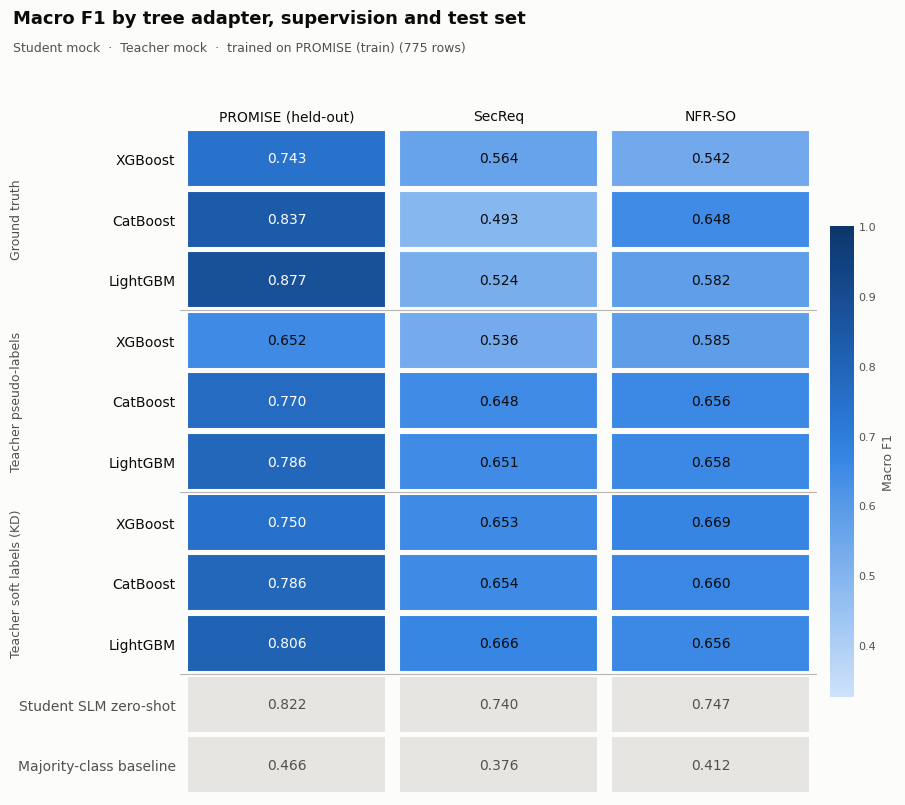

In [29]:
payload = result.payload()
plot_macro_f1_heatmap(payload);

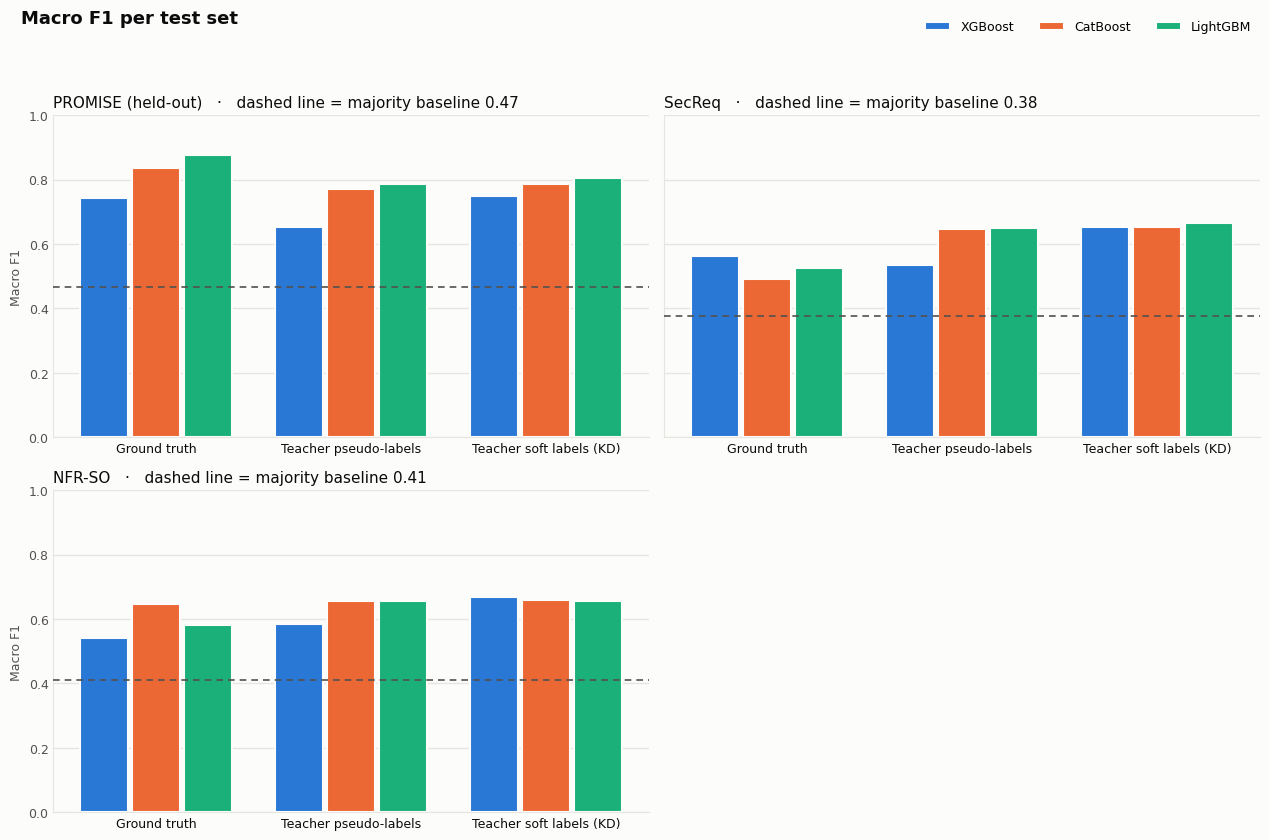

In [30]:
plot_macro_f1_bars(payload);

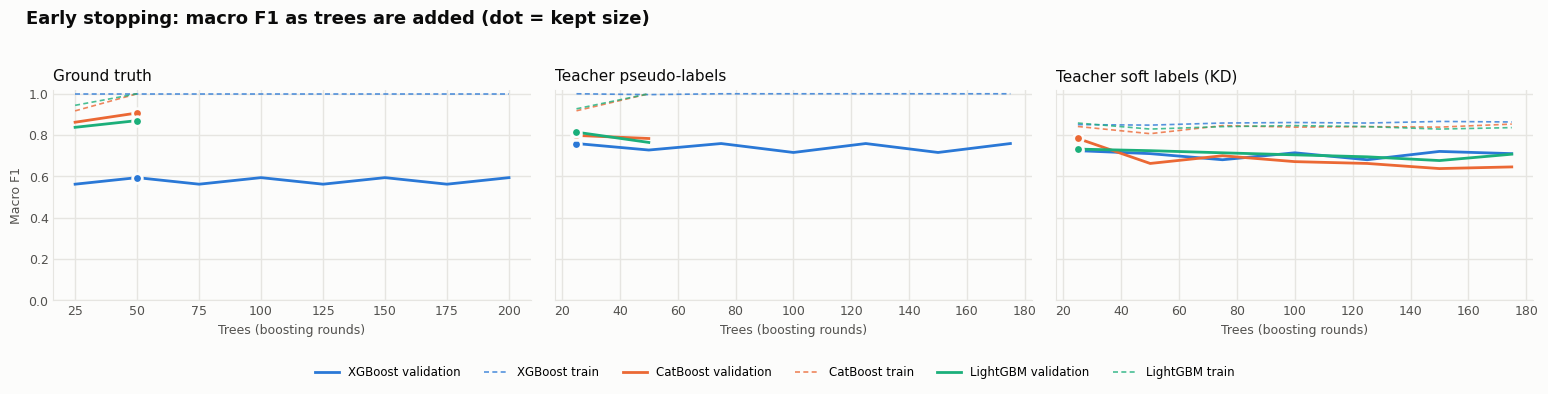

In [31]:
plot_training_curves(payload);

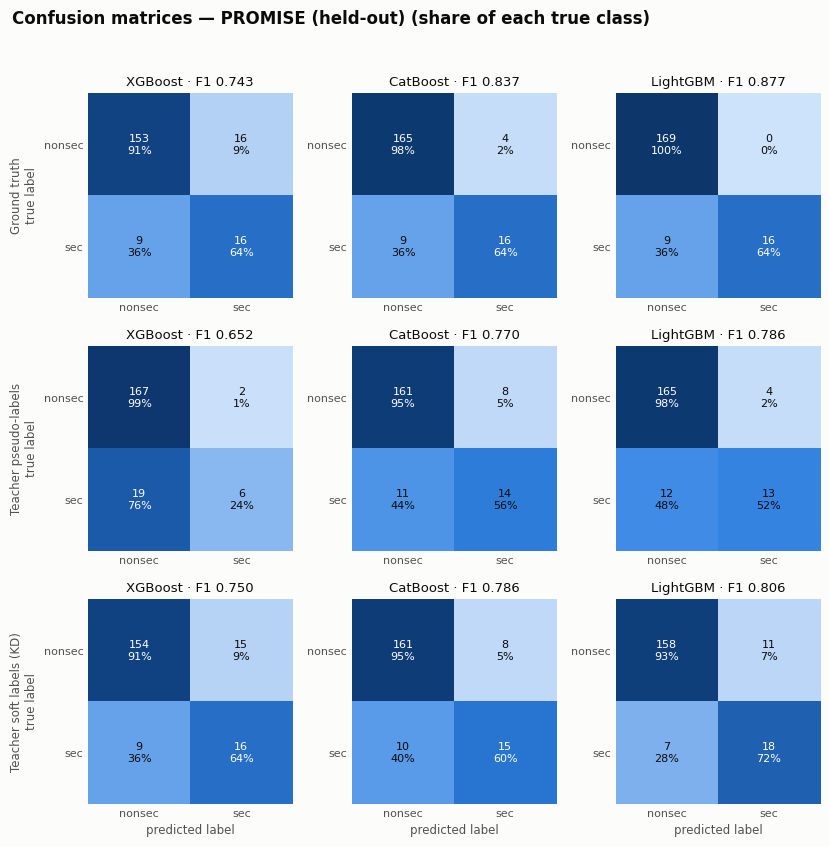

In [32]:
plot_confusion_matrices(payload, "PROMISE (held-out)");

### 11.3 Classifying new text with the in-memory models

In [33]:
new_texts = ["The system shall lock an account after five failed login attempts.",
             "The report page shall load within two seconds.",
             "All personal data shall be encrypted at rest."]
best_key = max(result.eval_rows, key=lambda r: r["macro_f1"] if r["test_set"] == "PROMISE (held-out)" else -1)["key"]
labels, proba = result.predict(new_texts, best_key)
print("Model:", best_key)
pd.DataFrame({"text": new_texts, "prediction": labels, **{f"p({c})": proba[:, i].round(3) for i, c in enumerate(result.classes)}})

Model: lightgbm__ground_truth


,text,prediction,p(nonsec),p(sec)
0,The system shall lock an account after five fa...,nonsec,0.536,0.464
1,The report page shall load within two seconds.,nonsec,0.934,0.066
2,All personal data shall be encrypted at rest.,sec,0.090,0.910


### 11.4 Reloading a saved run from disk

This is what the app's *Predict* tab does. The run is reloaded from `runs/`, each model is loaded at its early-stopped size, and the reloaded models must produce the same probabilities as the in-memory ones.

In [34]:
if SAVE_RUN:
    cascade = SavedCascade(run_dir, embedder=make_embedder(embedder_name),
                           student=MockStudentLLM(result.classes) if OFFLINE else None)
    reloaded_labels, reloaded_proba = cascade.predict(new_texts, best_key)
    assert np.allclose(reloaded_proba, proba, atol=1e-5), "reloaded model disagrees with the in-memory one"
    print(f"{len(cascade.model_keys)} models reloaded from {run_dir.name}; predictions match: {reloaded_labels}")

9 models reloaded from 20260915-014516_PROMISE_offline; predictions match: ['nonsec', 'nonsec', 'sec']


## 12 · Controlled simulations

This section replaces `scripts/simulate_gate_modes.py`. It runs two experiments on **synthetic 385-dim cascade features**, so they need no LLM, API key or download:

1. **Gate modes.** How should "learn only from mistakes" be ported to boosting? The candidates: the XGBoost objective gate with and without `gate_margin`, staged gating with a strict (0) and a soft (0.1) floor, and the ungated control.
2. **Distillation signal.** Training on gold labels vs a noisy Teacher's argmax vs the same Teacher's full soft distributions.

The synthetic data imitates the real features. The class signal lives in an 8-dim latent space mixed into 384 "embedding" columns (as MiniLM would spread it). A 385th Student-confidence column tracks difficulty. Gold labels carry 12% symmetric noise, so no model can separate the classes perfectly, which is what makes the gate's behaviour visible. Scores are measured against the **clean** labels, i.e. what each model actually learned.

The cells below use quick settings (1 seed, 150 trees). The saved figures in `results/` came from `--seeds 3 --n-estimators 300`.

In [35]:
SIM_SEEDS = 1            # the original script defaults to 3
SIM_N_ESTIMATORS = 150   # the original script defaults to 300

SCENARIOS = {"Binary, balanced": {"k": 2, "priors": [0.5, 0.5]},
             "Binary, 13% minority": {"k": 2, "priors": [0.87, 0.13]},
             "4-class, skewed": {"k": 4, "priors": [0.45, 0.25, 0.2, 0.1]}}

GATE_CONFIGS = [  # (row label, adapter, adapter kwargs)
    ("XGBoost · objective gate", "xgboost", {"gate_mode": "objective"}),
    ("XGBoost · objective, margin 0", "xgboost", {"gate_mode": "objective", "gate_margin": 0.0}),
    ("XGBoost · staged, floor 0", "xgboost", {"gate_mode": "staged", "gate_floor": 0.0}),
    ("XGBoost · staged, floor 0.1", "xgboost", {"gate_mode": "staged", "gate_floor": 0.1}),
    ("XGBoost · ungated", "xgboost", {"gate_mode": "none"}),
    ("CatBoost · staged, floor 0", "catboost", {"gate_mode": "staged", "gate_floor": 0.0}),
    ("CatBoost · staged, floor 0.1", "catboost", {"gate_mode": "staged", "gate_floor": 0.1}),
    ("CatBoost · ungated", "catboost", {"gate_mode": "none"}),
    ("LightGBM · staged, floor 0", "lightgbm", {"gate_mode": "staged", "gate_floor": 0.0}),
    ("LightGBM · staged, floor 0.1", "lightgbm", {"gate_mode": "staged", "gate_floor": 0.1}),
    ("LightGBM · ungated", "lightgbm", {"gate_mode": "none"}),
]


def make_task(k, priors, n=1500, seed=0, signal_dims=8, label_noise=0.12):
    """Synthetic features X, noisy gold labels, clean labels, and a noisy Teacher's soft labels."""
    rng = np.random.RandomState(seed)
    y = rng.choice(k, size=n, p=priors)
    centers = rng.randn(k, signal_dims) * 1.1
    latent = centers[y] + rng.randn(n, signal_dims)

    # Spread the low-dim signal across 384 "embedding" columns, plus noise.
    mixing = rng.randn(384, signal_dims) / np.sqrt(signal_dims)
    emb = latent @ mixing.T + rng.randn(n, 384) * 0.9

    # Bayes posterior from the latent geometry: what an ideal model believes.
    logits = -0.5 * ((latent[:, None, :] - centers[None]) ** 2).sum(-1) + np.log(priors)
    posterior = np.exp(logits - logits.max(1, keepdims=True))
    posterior /= posterior.sum(1, keepdims=True)

    # Student confidence: informative about difficulty, but noisy.
    student_conf = np.clip(posterior.max(1) + rng.randn(n) * 0.12, 1.0 / k, 1.0)
    X = np.hstack([emb, student_conf[:, None]]).astype(np.float32)

    # Gold labels with symmetric noise.
    flip = rng.rand(n) < label_noise
    y_gold = y.copy()
    y_gold[flip] = rng.randint(0, k, flip.sum())

    # Teacher: a tempered, noisy view of the posterior — its confidence carries information its argmax drops.
    t_logits = np.log(posterior + 1e-9) / 1.6 + rng.randn(n, k) * 0.9
    soft = np.exp(t_logits - t_logits.max(1, keepdims=True))
    soft /= soft.sum(1, keepdims=True)
    return X, y_gold, y, soft


def split_indices(n, seed):
    """60 / 15 / 25 train / validation / test."""
    idx = np.random.RandomState(seed + 99).permutation(n)
    return idx[:int(0.6 * n)], idx[int(0.6 * n):int(0.75 * n)], idx[int(0.75 * n):]


def macro_f1(y, p):
    return float(f1_score(y, p, average="macro", zero_division=0))


def mean_grid(rows, row_key, row_order, col_order, value="test_macro_f1"):
    """Mean of `value` per (row, scenario) cell."""
    grid = np.full((len(row_order), len(col_order)), np.nan)
    for i, r in enumerate(row_order):
        for j, c in enumerate(col_order):
            vals = [x[value] for x in rows if row_key(x) == r and x["scenario"] == c]
            if vals:
                grid[i, j] = np.mean(vals)
    return grid

### 12.1 Gate modes

Two things to look for: the **XGBoost objective gate with margin 0** collapsing, and **staged gating with floor 0** swinging between stages (the second heatmap, largest stage-to-stage jump in validation F1).

gate modes · Binary, balanced done
gate modes · Binary, 13% minority done
gate modes · 4-class, skewed done


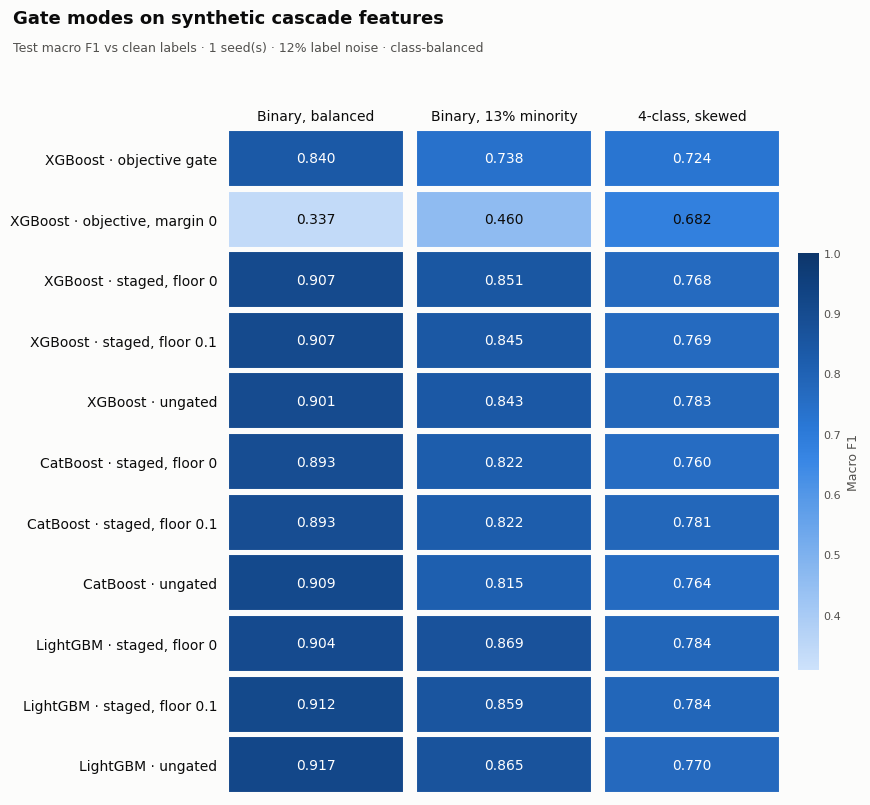

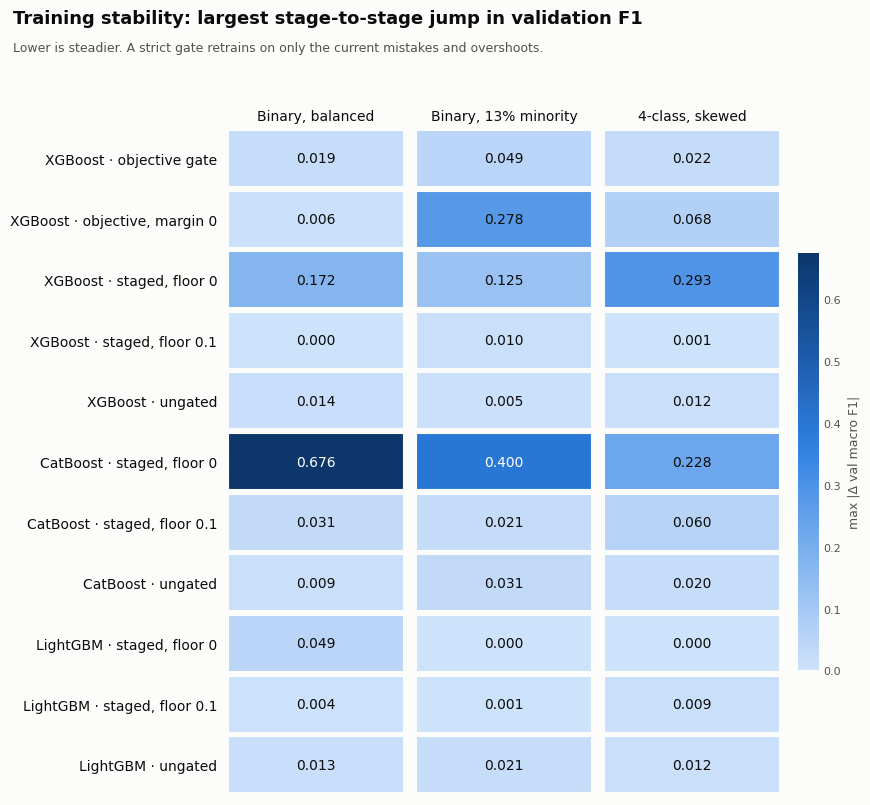

In [36]:
if RUN_SIMULATIONS:
    gate_rows = []
    for scen, spec in SCENARIOS.items():
        classes_sim = [f"c{i}" for i in range(spec["k"])]
        for seed in range(SIM_SEEDS):
            X, y_gold, y_clean, _ = make_task(spec["k"], spec["priors"], seed=seed)
            tr, va, te = split_indices(len(X), seed)
            for label, name, kwargs in GATE_CONFIGS:
                adapter = get_adapter(name, classes_sim, n_estimators=SIM_N_ESTIMATORS, class_weight="balanced",
                                      random_state=seed, **kwargs)
                adapter.fit(X[tr], y_gold[tr], X[va], y_gold[va])
                val = adapter.history["val_macro_f1"]
                gate_rows.append({"scenario": scen, "seed": seed, "config": label, "adapter": name,
                                  "test_macro_f1": macro_f1(y_clean[te], adapter.predict(X[te])),
                                  "val_swing": float(np.max(np.abs(np.diff(val)))) if len(val) > 1 else 0.0,
                                  "best_n_trees": int(adapter.best_n_trees)})
        print(f"gate modes · {scen} done")

    scen_names = list(SCENARIOS)
    gate_labels_sim = [c[0] for c in GATE_CONFIGS]
    gate_grid = mean_grid(gate_rows, lambda r: r["config"], gate_labels_sim, scen_names)
    swing_grid = mean_grid(gate_rows, lambda r: r["config"], gate_labels_sim, scen_names, value="val_swing")
    grid_heatmap(gate_grid, gate_labels_sim, scen_names, title="Gate modes on synthetic cascade features",
                 subtitle=f"Test macro F1 vs clean labels · {SIM_SEEDS} seed(s) · 12% label noise · class-balanced",
                 vmin=float(np.nanmin(gate_grid)) - 0.03)
    grid_heatmap(swing_grid, gate_labels_sim, scen_names,
                 title="Training stability: largest stage-to-stage jump in validation F1",
                 subtitle="Lower is steadier. A strict gate retrains on only the current mistakes and overshoots.",
                 vmin=0.0, vmax=max(0.3, float(np.nanmax(swing_grid))), value_label="max |Δ val macro F1|")
    plt.show()

### 12.2 Distillation signal

The question: does training on the Teacher's **soft** distributions beat training on its argmax, and how do both compare with the (noisy) gold labels? The grey reference row is the Teacher's own argmax score.

distillation · Binary, balanced done
distillation · Binary, 13% minority done
distillation · 4-class, skewed done


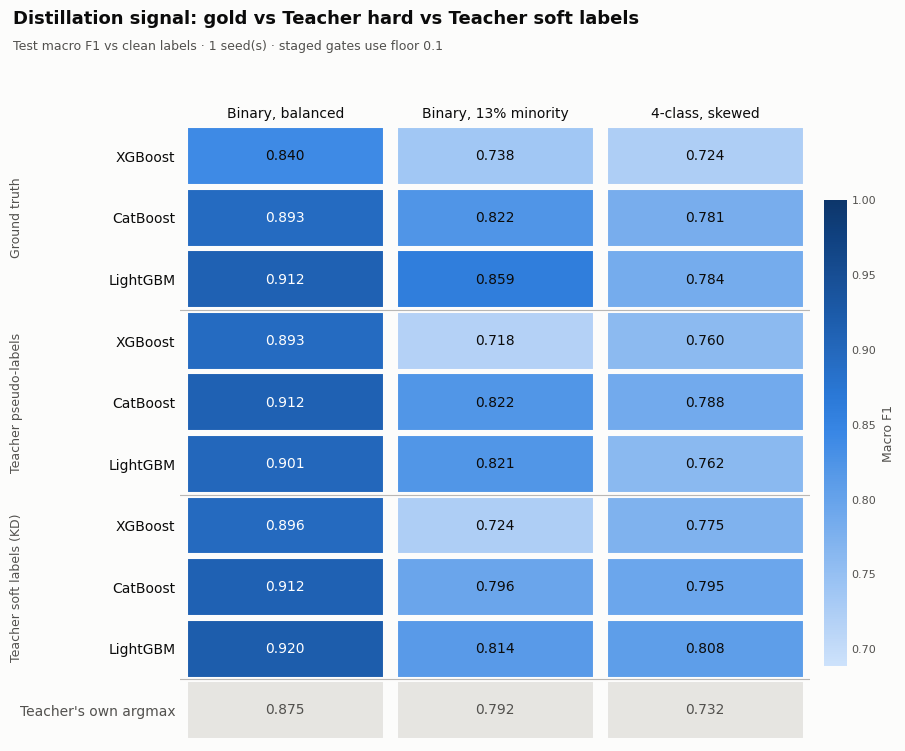

In [37]:
if RUN_SIMULATIONS:
    kd_rows = []
    for scen, spec in SCENARIOS.items():
        classes_sim = [f"c{i}" for i in range(spec["k"])]
        for seed in range(SIM_SEEDS):
            X, y_gold, y_clean, soft = make_task(spec["k"], spec["priors"], seed=seed)
            tr, va, te = split_indices(len(X), seed)
            hard = soft.argmax(1)
            teacher_f1 = macro_f1(y_clean[te], hard[te])
            for name in ADAPTER_ORDER:
                for supervision in SUPERVISIONS:
                    adapter = get_adapter(name, classes_sim, n_estimators=SIM_N_ESTIMATORS, class_weight="balanced",
                                          random_state=seed, gate_floor=0.1)
                    if supervision == "ground_truth":
                        adapter.fit(X[tr], y_gold[tr], X[va], y_gold[va])
                    elif supervision == "teacher_hard":
                        adapter.fit(X[tr], hard[tr], X[va], hard[va])
                    else:  # the same row expansion the pipeline uses
                        Xe, ye, we, src = expand_soft_labels(X[tr], soft[tr])
                        adapter.fit(Xe, ye, X[va], hard[va], sample_weight=we, gate_labels=hard[tr][src])
                    kd_rows.append({"scenario": scen, "seed": seed, "adapter": name, "supervision": supervision,
                                    "teacher_macro_f1": teacher_f1,
                                    "test_macro_f1": macro_f1(y_clean[te], adapter.predict(X[te]))})
        print(f"distillation · {scen} done")

    order = [(a, s) for s in SUPERVISION_ORDER for a in ADAPTER_ORDER]
    kd_grid = mean_grid(kd_rows, lambda r: (r["adapter"], r["supervision"]), order, scen_names)
    teacher_row = [[np.mean([r["teacher_macro_f1"] for r in kd_rows if r["scenario"] == c]) for c in scen_names]]
    grid_heatmap(kd_grid, [DISPLAY_NAME[a] for a, _ in order], scen_names,
                 title="Distillation signal: gold vs Teacher hard vs Teacher soft labels",
                 subtitle=f"Test macro F1 vs clean labels · {SIM_SEEDS} seed(s) · staged gates use floor 0.1",
                 reference_values=np.array(teacher_row), reference_labels=["Teacher's own argmax"],
                 blocks=[(SUPERVISION_LABEL[s], 3) for s in SUPERVISION_ORDER], vmin=float(np.nanmin(kd_grid)) - 0.03)
    plt.show()

## 13 · Sanity checks

This is a condensed version of `tests/`. Each check below reproduces one of the failure modes the project was built to prevent. No network is used: the Teacher's HTTP client and Ollama's `requests.post` are replaced by scripted fakes, and a virtual clock stands in for real sleeping.

In [38]:
from contextlib import contextmanager
from types import SimpleNamespace


@contextmanager
def virtual_clock():
    """Swap this notebook's global `time` for a clock that advances on sleep (no real waiting)."""
    real = globals()["time"]

    class Clock:
        def __init__(self):
            self.now, self.slept = real.monotonic(), []

        def sleep(self, seconds):
            self.slept.append(seconds)
            self.now += seconds

        def monotonic(self):
            return self.now

        def time(self):
            return real.time()

    clock = Clock()
    globals()["time"] = clock
    try:
        yield clock
    finally:
        globals()["time"] = real


# The checks provoke retries and failures on purpose; keep their log lines out of the output.
logger.setLevel(logging.CRITICAL)


def check(name, condition):
    assert condition, name
    print(f"✓ {name}")

### 13.1 The maths

In [39]:
# Soft-label row expansion: weighted CE over the copies == CE against the soft distribution.
rng = np.random.RandomState(0)
soft_demo = rng.dirichlet([1, 1, 1], size=5)
q = softmax(rng.randn(5, 3))                                   # any model's predicted probabilities
_, ye, we, src = expand_soft_labels(np.zeros((5, 1)), soft_demo, min_weight=0.0)
check("row expansion reproduces soft cross-entropy",
      np.isclose((we * -np.log(q[src, ye])).sum(), (soft_demo * -np.log(q)).sum()))

# The gate silences confidently-correct rows and keeps wrong or uncertain ones.
margins = np.array([[3.0, 0.0],    # correct, confident   -> silenced
                    [0.1, 0.0],    # correct, uncertain   -> kept (inside gate_margin)
                    [0.0, 3.0]])   # wrong                -> kept
g, h = gated_softmax_grad_hess(margins, np.array([0, 0, 0]), 2, gate_margin=0.10)
check("gate zeroes only the confident correct row", np.abs(g).sum(1).tolist()[0] == 0 and (np.abs(g).sum(1)[1:] > 0).all())
check("gated rows keep a small positive hessian", (h[0] > 0).all() and h[0].max() < 1e-5)

# Soft-label class balancing counts probability mass, not rows.
bw = _balanced_weights(np.array([0, 1, 0, 1]), np.array([0.9, 0.1, 0.8, 0.2]))
check("balanced weights equalise class mass under expansion",
      np.isclose(bw[[0, 2]].sum(), bw[[1, 3]].sum()))

✓ row expansion reproduces soft cross-entropy
✓ gate zeroes only the confident correct row
✓ gated rows keep a small positive hessian
✓ balanced weights equalise class mass under expansion


### 13.2 Teacher: batching, repair, rate limits and loud failure

In [40]:
TEACHER_CLASSES = ["sec", "nonsec"]


class FakeRateLimitError(Exception):
    """Stands in for openai.RateLimitError (matched by status code)."""
    status_code = 429

    def __init__(self, message="Rate limit reached. Please try again in 4.5s", headers=None):
        super().__init__(message)
        self.response = SimpleNamespace(status_code=429, headers=headers or {})


def fake_teacher(responder, headers=None, **kwargs):
    """OpenAITeacher whose chat-completions client replays `responder(call_number, kwargs)`."""
    kwargs.setdefault("tokens_per_minute", 10 ** 9)  # effectively unthrottled
    teacher = OpenAITeacher(api_key="test", model="fake-model", classes=TEACHER_CLASSES, **kwargs)
    calls = []

    def create(**kw):
        calls.append(kw)
        out = responder(len(calls), kw)
        if isinstance(out, Exception):
            raise out
        content, (prompt_toks, completion_toks) = out
        parsed = SimpleNamespace(choices=[SimpleNamespace(message=SimpleNamespace(content=content))],
                                 usage=SimpleNamespace(prompt_tokens=prompt_toks, completion_tokens=completion_toks,
                                                       total_tokens=prompt_toks + completion_toks))
        return SimpleNamespace(headers=headers or {}, parse=lambda: parsed)

    completions = SimpleNamespace(create=create)
    completions.with_raw_response = completions
    teacher._client = SimpleNamespace(chat=SimpleNamespace(completions=completions))
    return teacher, calls


def batch_json(indices, sec=0.9):
    return json.dumps({"results": [{"i": i, "sec": sec, "nonsec": round(1 - sec, 4)} for i in indices]})


with virtual_clock() as clock:
    t, calls = fake_teacher(lambda n, kw: (batch_json(range(25)), (700, 600)))
    t.generate_soft_labels([f"req {i}" for i in range(25)])
    check("25 texts cost one API call", len(calls) == 1)

    # A truncated batch keeps what parsed and re-issues only the missing index.
    t, calls = fake_teacher(lambda n, kw: (batch_json([0, 1], 0.8), (200, 100)) if n == 1
                            else ('{"sec": 0.3, "nonsec": 0.7}', (60, 20)), batch_size=3)
    out = t.generate_soft_labels(["a", "b", "c"])
    check("missing batch entry is repaired individually", len(calls) == 2 and round(out[2]["sec"], 2) == 0.3)

    # Five 429s are waited out on their own budget instead of burning the 3 ordinary retries.
    t, calls = fake_teacher(lambda n, kw: FakeRateLimitError() if n <= 5 else (batch_json([0, 1]), (200, 100)),
                            batch_size=2, max_retries=3)
    t.generate_soft_labels(["a", "b"])
    check("429s are waited out, not counted as failures", t.usage["rate_limit_hits"] == 5 and t.failed_indices == [])

    # An oversized retry-after (Groq once asked for 974 s) is capped at max_rate_limit_wait.
    t, _ = fake_teacher(lambda n, kw: FakeRateLimitError(headers={"retry-after": "974"}) if n == 1
                        else (batch_json([0, 1]), (200, 100)), batch_size=2)
    waits = []
    t._limiter.penalize = waits.append
    t.generate_soft_labels(["a", "b"])
    check("oversized retry-after is capped", max(waits) <= 121)

    # A per-day quota fails fast after one call instead of grinding through 8 retries.
    tpd = "Rate limit reached on tokens per day (TPD): Limit 200000, Used 199395. Please try again in 17m51s"
    t, calls = fake_teacher(lambda n, kw: FakeRateLimitError(tpd), batch_size=2)
    try:
        t.generate_soft_labels(["a", "b"])
        raised = False
    except DailyQuotaExhausted:
        raised = True
    check("daily quota raises immediately", raised and len(calls) == 1)

    # The original incident: nearly every call fails → must raise, not return uniform ties.
    t, calls = fake_teacher(lambda n, kw: FakeRateLimitError(), batch_size=1, max_rate_limit_retries=0)
    t._limiter.penalize = lambda s: None
    try:
        t.generate_soft_labels([f"text {i}" for i in range(20)])
        raised = False
    except TeacherFailureError:
        raised = True
    check("mass failure raises TeacherFailureError early", raised and len(calls) < 20)

    # Sliding window: 600 + 600 tokens > 1000/min must wait out the window.
    limiter = _RateLimiter(tokens_per_minute=1000, safety_factor=1.0)
    clock.slept.clear()
    limiter.acquire(600)
    limiter.acquire(600)
    check("rate limiter blocks once the token budget is spent", sum(clock.slept) >= 60)

check("retry durations parse", [_parse_duration(s) for s in ("12", "7.038s", "1m30s", "")] == [12.0, 7.038, 90.0, None])
check("a tie is not neutral: argmax of uniform picks the first class",
      max({"sec": 0.5, "nonsec": 0.5}, key={"sec": 0.5, "nonsec": 0.5}.get) == "sec")

✓ 25 texts cost one API call
✓ missing batch entry is repaired individually
✓ 429s are waited out, not counted as failures
✓ oversized retry-after is capped
✓ daily quota raises immediately
✓ mass failure raises TeacherFailureError early
✓ rate limiter blocks once the token budget is spent
✓ retry durations parse
✓ a tie is not neutral: argmax of uniform picks the first class


### 13.3 Student: logprob confidence and position debiasing

In [41]:
import requests


@contextmanager
def fake_ollama(handler):
    """Route requests.post to handler(payload) -> reply dict."""
    real_post, calls = requests.post, []

    def post(url, json=None, timeout=None):
        calls.append(json)
        return SimpleNamespace(raise_for_status=lambda: None, json=lambda: handler(json))

    requests.post = post
    try:
        yield calls
    finally:
        requests.post = real_post


def logprob_reply(letter_probs):
    """A /api/chat reply whose first token carries the given letter probabilities."""
    top = sorted(({"token": t, "logprob": math.log(p)} for t, p in letter_probs.items()), key=lambda e: -e["logprob"])
    return {"message": {"content": top[0]["token"]}, "logprobs": [{"token": top[0]["token"], "top_logprobs": top}]}


with fake_ollama(lambda p: logprob_reply({"A": 0.1, "B": 0.3, "The": 0.6})):
    _, c = OllamaLLM(TEACHER_CLASSES, debias=False).predict(["req"])
    check("confidence is renormalised over the offered letters", np.isclose(c[0], 0.75))

with fake_ollama(lambda p: logprob_reply({"A": 0.9, "B": 0.1})) as calls:   # a model that always answers "A"
    _, c_single = OllamaLLM(TEACHER_CLASSES, debias=False).predict(["req"])
    _, c_debiased = OllamaLLM(TEACHER_CLASSES, debias=True).predict(["req"])
    check("single order reads position bias as 90% confidence", np.isclose(c_single[0], 0.9))
    check("asking both orders cancels it to 50%", np.isclose(c_debiased[0], 0.5))

with fake_ollama(lambda p: {"message": {"content": "A"}} if p.get("logprobs")
                 else {"message": {"content": '{"label": "nonsec", "confidence": 0.8}'}}) as calls:
    llm = OllamaLLM(TEACHER_CLASSES)
    preds, c = llm.predict(["a", "b", "c"])
    check("no logprobs → JSON fallback, probed only once",
          preds[0] == "nonsec" and sum(1 for x in calls if x.get("logprobs")) == 1)

check("scoring mode is part of the cache identity",
      len({OllamaLLM(TEACHER_CLASSES).model_name, OllamaLLM(TEACHER_CLASSES, debias=False).model_name,
           OllamaLLM(TEACHER_CLASSES, scoring="json").model_name}) == 3)

logger.setLevel(logging.NOTSET)  # restore normal logging

✓ confidence is renormalised over the offered letters
✓ single order reads position bias as 90% confidence
✓ asking both orders cancels it to 50%
✓ no logprobs → JSON fallback, probed only once
✓ scoring mode is part of the cache identity


## 14 · Appendix

### 14.1 The Streamlit app (`app.py`)

`streamlit run app.py` wraps the same pipeline in five tabs:

| Tab | What it does |
|---|---|
| 📂 **Data** | Upload a file or pick a sample. Columns are guessed with `guess_columns`, and unlabelled data can be labelled by the Teacher alone. Per-class descriptions can be edited. Adds a held-out split plus uploaded or sample test sets. |
| 🚀 **Train** | Validates the setup (≥ 30 rows, ≥ 2 classes, ≤ 26 classes because the Student gets one option letter per class, API key present). Shows a cold-cache cost estimate and a *Test the Teacher connection* probe, then calls `run_experiment` with a stage-weighted progress bar. |
| 📊 **Results** | Warnings, diagnostics (Teacher agreement, dead-feature check, confidence↔correctness correlation), the score table with lift over baseline, the four charts from Section 10, and downloads. |
| 🔮 **Predict** | `SavedCascade` on any saved run. Models are ranked by mean test macro F1. Accepts pasted text or a file and returns CSV output. |
| ℹ️ **How it works** | Renders `docs/how_it_works.md`. That file is missing from this folder, so the tab raises `FileNotFoundError`. |

The sidebar picks *Real models* or *Offline demo*, the Ollama host/model, logprob vs JSON scoring, debiasing, a Teacher preset (warning when a local 70B needs more memory than the machine has), adapters, supervisions, per-adapter gate modes and boosting settings.

`.streamlit/config.toml` sets `fileWatcherType = "none"` because Streamlit's module watcher crashes while walking torch's lazy submodules, so restart the app after code edits. It also sets a 200 MB upload limit and the light theme with primary colour `#2a78d6`.

### 14.2 Command-line equivalents

```bash
# Section 11 — PROMISE → held-out + SecReq + NFR-SO with the real models
python scripts/run_benchmark.py
python scripts/run_benchmark.py --offline                       # mock models
python scripts/run_benchmark.py --train my.csv --text-col sentence --label-col category \
    --test other.csv --test-text-col sentence --test-label-col category

# Section 12 — full-size simulations (3 seeds, 300 trees) → results/simulation_*.{json,png}
python scripts/simulate_gate_modes.py

# Section 13 — the full test suite
python -m pytest tests
```

### 14.3 Things found while condensing

* **`OpenAITeacher.generate_soft_labels` is missing its `progress_callback` parameter** in `teasco_tree/llm/teacher.py`, so every call raises `NameError`. 21 of the 52 tests in `tests/` fail, and any non-mock Teacher run fails. Fixed in Section 4.3.
* `docs/how_it_works.md`, which the app's last tab reads, is not in the folder.
* The CatBoost adapter's docstring cites `tests/test_adapters.py::TestCatBoostGate`, which is not in the folder either.